# 16 Figures and facts of the Imsil summary report

This notebook draws the seven figures of the summary report `docs/reports/imsil_2025_summary_20261014/report.pdf` and writes the facts that the report quotes.
- **Figures.** Each is drawn here and saved as `figures/Figure_NN_<topic>.pdf` and `.png` (300 dpi) in the report folder. The style is the Haenam report's: Helvetica, 8 pt, panel letters, closed frames.
- **Facts.** Every number in `report.tex` is a macro `\F{key}` defined in `facts.tex`, which this notebook writes from `facts.json`. A fact is either computed here from the final products, or quoted from the executed output of the notebook that measured it. A quote is found with a pattern that must match exactly one value. Each fact records its source.

Nothing in the pipeline or the catalogs is changed.

| Figure | Content | Made from |
|---|---|---|
| 1 | Station map | `station_table/stations.csv`, `fmf_aligned/stations_imsil_5_20H.csv` |
| 2 | Swarm timeline: size and cumulative counts | `catalogs/fmf_final`, continuous data of 2–3 Nov 2025 (amplitude ratios, the notebook 12 code) |
| 3 | Geometry of the 101 well-located events | `catalogs/reference_25m_fmf` |
| 4 | Migration | same, with the notebook 11 functions |
| 5 | Long template-matching scan, 2018–2026 | long-scan catalog, `catalogs/fmf_long_candidates_evidence.csv` |
| 6 | Waveforms of the 2019-04-15 events against their templates | continuous data of 2019-04-15 and 2025-11-02 |
| 7 | Position of the 2019-04-15 events relative to the 2025 plane | `catalogs/*_2019A_full*`, `runs/hypodd_fmf_2019A_full/solo_A1A3` |

In [1]:
import os, sys, re, json, glob, time, hashlib, datetime, tempfile, warnings
import numpy as np, pandas as pd
warnings.filterwarnings('ignore', message='Discarding nonzero nanoseconds'); warnings.filterwarnings('ignore', category=FutureWarning)
os.environ.setdefault('HELVETICA_DIR', '/home/msseo/Download/Helvetica')
DL = '/home/msseo/works/72.2025_Imsil_swarm/DL_detection'; NBD = f'{DL}/notebooks'
REP = f'{DL}/docs/reports/imsil_2025_summary_20261014'; FIG = f'{REP}/figures'; os.makedirs(FIG, exist_ok=True)
sys.path.insert(0, f'{DL}/pipeline')
import config  # noqa: F401
import pathlib
import matplotlib as mpl, matplotlib.pyplot as plt, matplotlib.dates as mdates
from matplotlib import font_manager as fm
import obspy
from obspy import UTCDateTime
from scipy import stats as sps
from scipy.optimize import minimize_scalar
pd.set_option('display.width', 220); pd.set_option('display.max_colwidth', 200)
# Helvetica as in the Haenam summary report (moho 24.Slip_inversion/pipeline/notebooks/nbfont.py, pasted verbatim without its docstrings):
# regular/bold/italic faces built from URW NimbusSans (metric-compatible Helvetica clone; has Greek and superscripts) renamed Helvetica.
FONT_DIR = pathlib.Path.home() / ".local/share/fonts/helvetica-family"
USER_HELVETICA = pathlib.Path.home() / "Downloads/Helvetica/helvetica.ttf"
NIMBUS = "/usr/share/fonts/urw-base35/NimbusSans-{}.otf"
_REGULAR_SRC = (NIMBUS.format("Regular") if os.path.exists(NIMBUS.format("Regular"))
                else str(USER_HELVETICA))
SRC_REGULAR = pathlib.Path(_REGULAR_SRC)
_FACES = [
    (_REGULAR_SRC, "Helvetica-Regular.otf", "Regular", 400, False, False),
    (NIMBUS.format("Bold"), "Helvetica-Bold.otf", "Bold", 700, True, False),
    (NIMBUS.format("Italic"), "Helvetica-Italic.otf", "Italic", 400, False, True),
    (NIMBUS.format("BoldItalic"), "Helvetica-BoldItalic.otf", "Bold Italic", 700,
     True, True),
]
def _set_name(font, name_id, value):
    for rec in font["name"].names:
        if rec.nameID == name_id:
            rec.string = (value.encode("utf-16-be") if rec.platformID == 3
                          else value.encode("latin-1"))
def build_helvetica_family(force=False):
    have = [FONT_DIR / f[1] for f in _FACES]
    if not force and all(p.exists() for p in have):
        return True
    if not SRC_REGULAR.exists():
        return False
    from fontTools.ttLib import TTFont
    FONT_DIR.mkdir(parents=True, exist_ok=True)
    for src, outname, sub, wght, is_bold, is_ital in _FACES:
        if not os.path.exists(src):
            continue
        f = TTFont(src)
        full = "Helvetica" if sub == "Regular" else f"Helvetica {sub}"
        ps = "Helvetica" if sub == "Regular" else "Helvetica-" + sub.replace(" ", "")
        _set_name(f, 1, "Helvetica")
        _set_name(f, 2, sub)
        _set_name(f, 4, full)
        _set_name(f, 6, ps)
        _set_name(f, 16, "Helvetica")
        _set_name(f, 17, sub)
        os2 = f["OS/2"]
        os2.usWeightClass = wght
        fs = os2.fsSelection & ~(1 | (1 << 5) | (1 << 6))
        if is_ital:
            fs |= 1
        if is_bold:
            fs |= (1 << 5)
        if not is_bold and not is_ital:
            fs |= (1 << 6)
        os2.fsSelection = fs
        ms = f["head"].macStyle & ~3
        if is_bold:
            ms |= 1
        if is_ital:
            ms |= 2
        f["head"].macStyle = ms
        f.save(FONT_DIR / outname)
    return (FONT_DIR / _FACES[0][1]).exists()
def use_helvetica(verbose=False):
    ok = build_helvetica_family()
    if ok:
        for f in fm.findSystemFonts([str(FONT_DIR)]):
            fm.fontManager.addfont(f)
    have = {e.name for e in fm.fontManager.ttflist}
    fam = ["Helvetica", "Nimbus Sans", "DejaVu Sans"]
    plt.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": fam,
        "mathtext.fontset": "custom",
        "mathtext.rm": "Helvetica",
        "mathtext.it": "Helvetica:italic",
        "mathtext.bf": "Helvetica:bold",
        "mathtext.sf": "Helvetica",
        "mathtext.default": "regular",
        "axes.unicode_minus": False,
        "legend.framealpha": 1.0,
        "legend.facecolor": "white",
        "pdf.fonttype": 42,          # embed TrueType so vector output stays editable
        "ps.fonttype": 42,
        "svg.fonttype": "none",
    })
    resolved = "Helvetica" if "Helvetica" in have else (
        "Nimbus Sans" if "Nimbus Sans" in have else "DejaVu Sans")
    if verbose:
        n = len([e for e in fm.fontManager.ttflist if e.name == "Helvetica"])
        print(f"font family in use: {resolved} ({n} faces registered)")
    return resolved
DPI = 300
assert use_helvetica(verbose=True) == 'Helvetica'
assert 'Bold' in fm.findfont(fm.FontProperties(family='Helvetica', weight='bold')), fm.findfont(fm.FontProperties(family='Helvetica', weight='bold'))
plt.rcParams.update({"font.size": 8, "axes.labelsize": 8.5, "axes.titlesize": 8.5, "xtick.labelsize": 7.5, "ytick.labelsize": 7.5, "legend.fontsize": 7.5,
                     "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6, "xtick.major.size": 3, "ytick.major.size": 3,
                     "savefig.dpi": DPI, "pdf.fonttype": 42, "legend.framealpha": 1.0, "legend.edgecolor": "0.3", "legend.fancybox": False})
def letter(ax, s, x=-0.02):
    ax.annotate(f"({s})", xy=(x, 1.0), xycoords="axes fraction", xytext=(0, 5.5), textcoords="offset points", ha="right", va="bottom", fontsize=9.5, fontweight="bold")
SOURCES = {}
def sha(p): return hashlib.sha256(open(p, 'rb').read()).hexdigest()
def record(stem, *paths): SOURCES.setdefault(stem, []).extend(dict(path=os.path.relpath(p, DL), sha256=sha(p)) for p in paths)
def save(fig, stem):
    fig.savefig(f'{FIG}/{stem}.pdf', bbox_inches='tight', pad_inches=0.03, facecolor='white')
    fig.savefig(f'{FIG}/{stem}.png', bbox_inches='tight', pad_inches=0.03, facecolor='white', dpi=DPI)
    plt.show()
# facts: key -> dict(value (LaTeX text), source, how)
FACTS = {}
def tex(s): return str(s).replace('\\', '').replace('%', r'\%').replace('&', r'\&').replace('_', r'\_').replace('#', r'\#')
def fact(key, value, source, how=''):
    assert key not in FACTS, key
    FACTS[key] = dict(value=tex(value), source=source, how=how); return value
def nbout(name):
    nb = json.load(open(f'{NBD}/{name}')); parts = []
    for c in nb['cells']:
        for o in c.get('outputs', []):
            if o['output_type'] == 'stream': parts.append(''.join(o['text']))
            elif o['output_type'] == 'error': raise RuntimeError(f'{name} carries an error output')
            elif 'data' in o:
                d = o['data']
                if 'text/plain' in d: parts.append(''.join(d['text/plain']))
                if 'text/html' in d: parts.append(re.sub(r'<[^>]+>', ' ', ''.join(d['text/html'])).replace('&lt;', '<').replace('&gt;', '>').replace('&amp;', '&'))
    return '\n'.join(parts)
OUTS = {}
def grab(name, pattern):
    if name not in OUTS: OUTS[name] = nbout(name)
    m = set(re.findall(pattern, OUTS[name])); assert len(m) == 1, (name, pattern, m)
    return m.pop()
def quote(key, name, pattern, fmt=None, how=''):
    v = grab(name, pattern); return fact(key, fmt(v) if fmt else v, f'notebooks/{name}', how)
print('report folder:', REP)

font family in use: Helvetica (4 faces registered)
report folder: /home/msseo/works/72.2025_Imsil_swarm/DL_detection/docs/reports/imsil_2025_summary_20261014


## Inputs and the counts that every later section uses

In [2]:
STA = pd.read_csv(f'{DL}/station_table/stations.csv'); FMFSTA = pd.read_csv(f'{DL}/fmf_aligned/stations_imsil_5_20H.csv')
LONGSTA = pd.read_csv(f'{DL}/fmf_aligned/stations_imsil_5_20H_long.csv')
DLC = pd.read_csv(f'{DL}/catalogs/imsil_dl_catalog.csv', parse_dates=['time'])
DLR = pd.read_csv(f'{DL}/catalogs/imsil_dl_relocated.csv', dtype={'event_id': str})
REF = pd.read_csv(f'{DL}/catalogs/reference_25m/DL_reference_25m.csv', dtype={'event_id': str})
KMA = pd.read_csv(f'{DL}/catalogs/imsil_kma24.csv', parse_dates=['origin_time_UTC'])
FMF = pd.read_csv(f'{DL}/catalogs/fmf_final/imsil_fmf_catalog.csv', parse_dates=['origin']).sort_values('origin').reset_index(drop=True)
REL = pd.read_csv(f'{DL}/catalogs/imsil_fmf_relocated.csv', dtype={'event_id': str})
R25 = pd.read_csv(f'{DL}/catalogs/reference_25m_fmf/DL_reference_25m.csv', dtype={'event_id': str}); R25['time'] = pd.to_datetime(R25.origin_time_reloc)
TPL = pd.read_csv(f'{DL}/catalogs/imsil_templates_ref25.csv', dtype={'event_id': str})
LONG_CSV = f'{DL}/fmf_aligned/catalogs/fmf_imsil_catalog_imsil_5_20H_aligned_mad10_long_seg.csv'
LONG = pd.read_csv(LONG_CSV, parse_dates=['origin']); EVD = pd.read_csv(f'{DL}/catalogs/fmf_long_candidates_evidence.csv', parse_dates=['origin'])
DEC = pd.read_csv(f'{DL}/docs/decisions.csv').set_index('id')
for p in (f'{DL}/station_table/stations.csv', f'{DL}/catalogs/fmf_final/imsil_fmf_catalog.csv', f'{DL}/catalogs/reference_25m_fmf/DL_reference_25m.csv', LONG_CSV): record('inputs', p)
SRC = (35.5506, 127.2951)                                   # decision R2: ML 1.9 hand-pick HYPOINVERSE epicenter (kim2011)
fact('meta.date', '14 October 2026', 'this notebook')
fact('data.n_sta', len(STA), 'station_table/stations.csv', 'KS stations within 100 km (KWJU dropped, D2)')
fact('data.n_fmf_sta', len(FMFSTA), 'fmf_aligned/stations_imsil_5_20H.csv')
fact('data.fmf_s_on_z', ', '.join(FMFSTA[FMFSTA.horizontals == 0].station), 'fmf_aligned/stations_imsil_5_20H.csv', 'S window on Z (D12)')
fact('data.long_s_on_z_n', int((LONGSTA.horizontals == 0).sum()), 'fmf_aligned/stations_imsil_5_20H_long.csv', 'D26')
fact('data.n_days', DLC.time.dt.normalize().nunique(), 'catalogs/imsil_dl_catalog.csv', 'days with located events')
# DL catalog (nb03)
fact('dl.n_located', f'{len(DLC):,}', 'catalogs/imsil_dl_catalog.csv'); fact('dl.n_A', int((DLC.tier == 'A').sum()), 'catalogs/imsil_dl_catalog.csv'); fact('dl.n_B', int((DLC.tier == 'B').sum()), 'catalogs/imsil_dl_catalog.csv')
fact('dl.n_box', int(DLC.in_imsil_box.sum()), 'catalogs/imsil_dl_catalog.csv'); fact('dl.n_box_AB', int((DLC.in_imsil_box & DLC.tier.isin(['A', 'B'])).sum()), 'catalogs/imsil_dl_catalog.csv')
quote('dl.n_P', '03_full_DL_catalog.ipynb', r'Picks \(P / S\)\s+(\d+) / \d+', lambda v: f'{int(v):,}'); quote('dl.n_S', '03_full_DL_catalog.ipynb', r'Picks \(P / S\)\s+\d+ / (\d+)', lambda v: f'{int(v):,}')
quote('dl.box_before', '03_full_DL_catalog.ipynb', r'before the swarm (\d+), swarm window \d+, after \d+'); quote('dl.box_swarm', '03_full_DL_catalog.ipynb', r'before the swarm \d+, swarm window (\d+), after \d+')
quote('dl.box_after', '03_full_DL_catalog.ipynb', r'before the swarm \d+, swarm window \d+, after (\d+)')
quote('dl.kma_region', '03_full_DL_catalog.ipynb', r'and (\d+ of \d+) KMA events in the region')
quote('dl.kma_imsil', '03_full_DL_catalog.ipynb', r'recovers (\d+ of the \d+) KMA-listed Imsil events', lambda v: v.replace(' the', ''))
quote('dl.shallow_box', '04_relocation_and_25m_reference.ipynb', r'D5: in-box A/B events shallower than 10 km\s+(\d+)')
# smoke test (nb02)
quote('smoke.epi_km', '02_smoke_test_swarm_days.ipynb', r'ML 1.9 locates ([\d.]+) km from its hand-pick')
quote('smoke.depth_km', '02_smoke_test_swarm_days.ipynb', r'from its hand-pick epicentre, at ([\d.]+) km depth')
quote('smoke.dP', '02_smoke_test_swarm_days.ipynb', r'Median \|PhaseNet\+ - hand\| P \(s\)\s+([\d.]+)'); quote('smoke.dS', '02_smoke_test_swarm_days.ipynb', r'Median \|PhaseNet\+ - hand\| S \(s\)\s+([\d.]+)')
# relocation of the DL events (nb04)
fact('rel.n_sub', len(DLR), 'catalogs/imsil_dl_relocated.csv'); fact('rel.n_ref', len(REF), 'catalogs/reference_25m/DL_reference_25m.csv')
quote('rel.kma_in_ref', '04_relocation_and_25m_reference.ipynb', r'KMA-listed events in the reference\s+(\d+ of \d+)')
for c_, k_ in (('ex95_m', 'E'), ('ey95_m', 'N'), ('ez95_m', 'Z')): fact(f'rel.med95_{k_}', f'{REF[c_].median():.1f}', 'catalogs/reference_25m/DL_reference_25m.csv', 'median 95 % half-width')
quote('rel.plane04', '04_relocation_and_25m_reference.ipynb', r'Haenam SVD fit gives (\d+ deg / \d+ deg)', lambda v: v.replace(' deg', '°'))
quote('rel.ext04', '04_relocation_and_25m_reference.ipynb', r'occupies about (\d+ m east-west, \d+ m north-south and \d+ m in depth)', lambda v: v.replace('east-west', 'east–west').replace('north-south', 'north–south'))
quote('rel.flip04', '04_relocation_and_25m_reference.ipynb', r'(\d+) of 1000 resamples flip')
quote('rel.strike04', '04_relocation_and_25m_reference.ipynb', r'strike spans (\d+-\d+) deg', lambda v: v.replace('-', '–') + '°'); quote('rel.dip04', '04_relocation_and_25m_reference.ipynb', r'and the dip (\d+-\d+) deg', lambda v: v.replace('-', '–') + '°')
quote('rel.prev_res', '04_relocation_and_25m_reference.ipynb', r'median residuals (\d+, \d+, \d+) m')
quote('rel.prev_n', '04_relocation_and_25m_reference.ipynb', r'Earlier 18-event relocation: matched; median \|[^\n]*?\s(\d+); \d+, \d+, \d+')
display(pd.DataFrame(FACTS).T[['value', 'source']])

,value,source
meta.date,14 October 2026,this notebook
data.n_sta,54,station_table/stations.csv
data.n_fmf_sta,22,fmf_aligned/stations_imsil_5_20H.csv
data.fmf_s_on_z,"NAWB, KWJ2",fmf_aligned/stations_imsil_5_20H.csv
data.long_s_on_z_n,9,fmf_aligned/stations_imsil_5_20H_long.csv
data.n_days,151,catalogs/imsil_dl_catalog.csv
dl.n_located,"1,695",catalogs/imsil_dl_catalog.csv
dl.n_A,529,catalogs/imsil_dl_catalog.csv
dl.n_B,659,catalogs/imsil_dl_catalog.csv
dl.n_box,125,catalogs/imsil_dl_catalog.csv


In [3]:
# magnitudes (nb05, nb05a)
quote('ml.n_primary_ref', '05_local_magnitudes.ipynb', r'Primary ML exists for (\d+ of \d+) reference events')
quote('ml.dkma_med', '05_local_magnitudes.ipynb', r'Primary ML - KMA ML: median, RMS\s+(-?[\d.]+), [\d.]+', lambda v: v.replace('-', '−'))
quote('ml.dkma_rms', '05_local_magnitudes.ipynb', r'Primary ML - KMA ML: median, RMS\s+-?[\d.]+, ([\d.]+)')
quote('ml.nawb', '05_local_magnitudes.ipynb', r'NAWB / KWJ2 / EURB median residual\s+([+\-][\d.]+) / [+\-][\d.]+ / [+\-][\d.]+', lambda v: v.replace('-', '−'))
quote('ml.kwj2', '05_local_magnitudes.ipynb', r'NAWB / KWJ2 / EURB median residual\s+[+\-][\d.]+ / ([+\-][\d.]+) / [+\-][\d.]+', lambda v: v.replace('-', '−'))
quote('ml.eurb', '05_local_magnitudes.ipynb', r'NAWB / KWJ2 / EURB median residual\s+[+\-][\d.]+ / [+\-][\d.]+ / ([+\-][\d.]+)', lambda v: v.replace('-', '−'))
quote('ml.nawb_B', '05a_response_precedence.ipynb', r'NAWB residual: A raw / B raw\s+[+\-][\d.]+ / ([+\-][\d.]+)', lambda v: v.replace('-', '−'))
quote('ml.kwj2_B', '05a_response_precedence.ipynb', r'KWJ2 residual: A raw / B raw\s+[+\-][\d.]+ / ([+\-][\d.]+)', lambda v: v.replace('-', '−'))
quote('ml.n_primary_B', '05a_response_precedence.ipynb', r'Primary ML count: A / A raw / B raw\s+\d+ / \d+ / (\d+)')
quote('ml.anchors', '05_local_magnitudes.ipynb', r'Possible relative-ML anchors \(>= 20 picked\)\s+(\d+)')
# template matching (nb06-nb09)
fact('fmf.n_tpl', len(TPL), 'catalogs/imsil_templates_ref25.csv'); fact('fmf.n_det', len(FMF), 'catalogs/fmf_final/imsil_fmf_catalog.csv')
fact('fmf.n_ref', int(FMF.is_reference.sum()), 'catalogs/fmf_final'); fact('fmf.n_new', int(FMF.is_new.sum()), 'catalogs/fmf_final')
win = (FMF.origin >= '2025-11-02 19:30') & (FMF.origin <= '2025-11-03 01:30')
fact('fmf.n_window', int(win.sum()), 'catalogs/fmf_final', '2025-11-02 19:30 to 11-03 01:30 UTC'); fact('fmf.late', FMF.origin[~win].dt.strftime('%H:%M:%S').iloc[0], 'catalogs/fmf_final', 'the one detection after the window (3 Nov)')
assert (~win).sum() == 1
c5 = FMF.template_cuspid.value_counts(); fact('fmf.top_tpl', int(c5.index[0]), 'catalogs/fmf_final'); fact('fmf.top_tpl_n', int(c5.iloc[0]), 'catalogs/fmf_final')
fact('fmf.top_tpl_eid', TPL.set_index('cuspid').event_id[int(c5.index[0])], 'catalogs/imsil_templates_ref25.csv')
quote('fmf.selfcc_frozen', '06_fmf_template_matching.ipynb', r'Self-detection CC, median \(min\): frozen / aligned\s+([\d.]+) \([\d.]+\) / [\d.]+')
quote('fmf.selfcc_aligned', '06_fmf_template_matching.ipynb', r'Self-detection CC, median \(min\): frozen / aligned\s+[\d.]+ \([\d.]+\) / ([\d.]+)')
eff = DEC.loc['D23', 'effect_on_counts']; m = re.fullmatch(r'(\d+) -> (\d+) \(12x no floor\), (\d+) \(10x floor\), (\d+) \(10x no floor\)', eff.strip()); assert m, eff
for k_, v_ in zip(('fmf.n_12f', 'fmf.n_12nf', 'fmf.n_10f', 'fmf.n_10nf'), m.groups()): fact(k_, v_, 'docs/decisions.csv D23')
assert int(m.group(4)) == len(FMF)
quote('vet.iso', '08_vet_new_fmf_detections.ipynb', r'Isolated / within 15 s of a stronger detection\s+(\d+) / \d+'); quote('vet.near', '08_vet_new_fmf_detections.ipynb', r'Isolated / within 15 s of a stronger detection\s+\d+ / (\d+)')
quote('vet.ab_iso', '08_vet_new_fmf_detections.ipynb', r'\(a\) and \(b\) pass: isolated / near stronger\s+(\d+) / \d+'); quote('vet.ab_near', '08_vet_new_fmf_detections.ipynb', r'\(a\) and \(b\) pass: isolated / near stronger\s+\d+ / (\d+)')
# joint relocation (nb10)
fact('jr.n_rel', len(REL), 'catalogs/imsil_fmf_relocated.csv'); fact('jr.n_rel_det', int((REL.kind == 'detection').sum()), 'catalogs/imsil_fmf_relocated.csv')
fact('jr.n25', len(R25), 'catalogs/reference_25m_fmf'); fact('jr.n25_det', int((R25.kind == 'detection').sum()), 'catalogs/reference_25m_fmf')
quote('jr.ext', '10_fmf_joint_relocation.ipynb', r'\b101; (\d+ / \d+ / \d+)\b', lambda v: v.replace(' / ', ', '))
quote('jr.strike_ci', '10_fmf_joint_relocation.ipynb', r'268\.7 / 88\.2; (\d+-\d+); \d+-\d+', lambda v: v.replace('-', '–') + '°'); quote('jr.dip_ci', '10_fmf_joint_relocation.ipynb', r'268\.7 / 88\.2; \d+-\d+; (\d+-\d+)', lambda v: v.replace('-', '–') + '°')
quote('jr.hw_ref', '10_fmf_joint_relocation.ipynb', r'([\d.]+ / [\d.]+ / [\d.]+); [\d.]+ / [\d.]+ / [\d.]+\s', lambda v: v.replace(' / ', ', ')); quote('jr.hw_det', '10_fmf_joint_relocation.ipynb', r'[\d.]+ / [\d.]+ / [\d.]+; ([\d.]+ / [\d.]+ / [\d.]+)\s', lambda v: v.replace(' / ', ', '))
display(pd.DataFrame(FACTS).T[['value', 'source']].tail(40))

,value,source
rel.prev_res,"1, 1, 2",notebooks/04_relocation_and_25m_reference.ipynb
rel.prev_n,17,notebooks/04_relocation_and_25m_reference.ipynb
ml.n_primary_ref,8 of 28,notebooks/05_local_magnitudes.ipynb
ml.dkma_med,−0.13,notebooks/05_local_magnitudes.ipynb
ml.dkma_rms,0.17,notebooks/05_local_magnitudes.ipynb
ml.nawb,+0.54,notebooks/05_local_magnitudes.ipynb
ml.kwj2,−0.55,notebooks/05_local_magnitudes.ipynb
ml.eurb,−0.46,notebooks/05_local_magnitudes.ipynb
ml.nawb_B,+0.04,notebooks/05a_response_precedence.ipynb
ml.kwj2_B,+0.15,notebooks/05a_response_precedence.ipynb


## Method parameters, read from the frozen settings files

In [4]:
FR_ = json.load(open(f'{DL}/logs/full_run_params.json')); FS_ = json.load(open(f'{DL}/catalogs/fmf_final/settings.json')); MAN_ = json.load(open(f'{DL}/catalogs/reference_25m_fmf/selection_manifest.json'))
RC_ = open(f'{DL}/reloc/imsil_dl_cluster_config.py').read()
for k_ in ('xcorr: 1000 Hz lanczos, 5-20 Hz, +/-0.5 s window, cc >= 0.7', 'OBSCC = 4'): assert k_ in RC_, k_
assert '<= 25 m' in MAN_['selection']
rs = FR_['REGION_STRICT']; qc = FR_['HAENAM_QC']
fact('p.pmin', FR_['PNPLUS_MIN_PROB'], 'logs/full_run_params.json'); fact('p.fs', f"{FR_['SAMPLING_RATE']:.0f}", 'logs/full_run_params.json')
fact('p.n_picks', rs['n_picks'], 'logs/full_run_params.json'); fact('p.n_p', rs['n_p_picks'], 'logs/full_run_params.json'); fact('p.n_s', rs['n_s_picks'], 'logs/full_run_params.json'); fact('p.n_ps', rs['n_p_and_s_picks'], 'logs/full_run_params.json')
fact('p.box_lat', f"{rs['lat'][0]:.2f}–{rs['lat'][1]:.2f}° N", 'logs/full_run_params.json'); fact('p.box_lon', f"{rs['lon'][0]:.2f}–{rs['lon'][1]:.2f}° E", 'logs/full_run_params.json'); fact('p.zlim', f"{rs['zlim'][0]}–{rs['zlim'][1]}", 'logs/full_run_params.json')
fact('p.gap', f"{qc['gap']:.0f}", 'logs/full_run_params.json'); fact('p.num', qc['num'], 'logs/full_run_params.json'); fact('p.rms', f"{qc['rms']:.0f}", 'logs/full_run_params.json'); fact('p.err', f"{qc['erh']:.0f}", 'logs/full_run_params.json')
fact('p.zfloor', re.search(r'(\d+) km', DEC.loc['D5', 'imsil_default']).group(1), 'docs/decisions.csv D5')
fact('p.xc_band', '5–20', 'reloc/imsil_dl_cluster_config.py'); fact('p.xc_cc', '0.7', 'reloc/imsil_dl_cluster_config.py'); fact('p.xc_win', '0.5', 'reloc/imsil_dl_cluster_config.py'); fact('p.xc_interp', '1,000', 'reloc/imsil_dl_cluster_config.py'); fact('p.obscc', '4', 'reloc/imsil_dl_cluster_config.py')
assert int(REF.n_boot.max()) == 1000 and int(R25.n_boot.max()) == 1000; fact('p.nboot', '1,000', 'catalogs/reference_25m*/ n_boot'); fact('p.bound', '25', 'catalogs/reference_25m_fmf/selection_manifest.json')
fact('p.fmf_band', '–'.join(str(x) for x in FS_['band_hz']), 'catalogs/fmf_final/settings.json'); fact('p.fmf_mad', f"{FS_['threshold']['mad_k']:.0f}", 'catalogs/fmf_final/settings.json')
fact('p.fmf_minsta', FS_['threshold']['min_present_stations'], 'catalogs/fmf_final/settings.json'); fact('p.fmf_merge', f"{FS_['threshold']['merge_s']:.0f}", 'catalogs/fmf_final/settings.json'); fact('p.fmf_snr', FS_['template_snr_gate'], 'catalogs/fmf_final/settings.json')
assert FS_['windows'] == {'P': '1.5 s on Z from P-0.5 s', 'S': '2.0 s from S-0.5 s'} and FS_['threshold']['abs_cc_floor'] is None
fact('p.fmf_pwin', '1.5', 'catalogs/fmf_final/settings.json'); fact('p.fmf_swin', '2.0', 'catalogs/fmf_final/settings.json'); fact('p.fmf_pre', '0.5', 'catalogs/fmf_final/settings.json')
quote('dl.days', '03_full_DL_catalog.ipynb', r'Days with picks / days in period\s+(\d+ / \d+)', lambda v: v.split(' / ')[1])
fact('kma.n', len(KMA), 'catalogs/imsil_kma24.csv'); fact('kma.ml', f'{KMA.ML.min():.1f}–{KMA.ML.max():.1f}', 'catalogs/imsil_kma24.csv')
t0_, t1_ = KMA.origin_time_UTC.min(), KMA.origin_time_UTC.max(); fact('kma.t0', t0_.strftime('%H:%M'), 'catalogs/imsil_kma24.csv'); fact('kma.t1', t1_.strftime('%H:%M'), 'catalogs/imsil_kma24.csv')
fact('kma.t0_kst', (t0_ + pd.Timedelta(hours=9)).strftime('%H:%M'), 'catalogs/imsil_kma24.csv', 'KST = UTC + 9 h'); fact('kma.t1_kst', (t1_ + pd.Timedelta(hours=9)).strftime('%H:%M'), 'catalogs/imsil_kma24.csv')
fact('kma.dur', f'{(t1_ - t0_).total_seconds() / 3600:.1f}', 'catalogs/imsil_kma24.csv', 'hours'); fact('kma.mlmax_t', KMA.loc[KMA.ML.idxmax(), 'origin_time_UTC'].strftime('%H:%M:%S'), 'catalogs/imsil_kma24.csv')
fact('long.imsb_start', re.search(r'IMSB from (\d{4}-\d{2}-\d{2})', DEC.loc['D25', 'evidence']).group(1), 'docs/decisions.csv D25')
display(pd.DataFrame(FACTS).T[['value', 'source']].tail(45))

,value,source
jr.n25_det,73,catalogs/reference_25m_fmf
jr.ext,"210, 29, 209",notebooks/10_fmf_joint_relocation.ipynb
jr.strike_ci,267–271°,notebooks/10_fmf_joint_relocation.ipynb
jr.dip_ci,87–90°,notebooks/10_fmf_joint_relocation.ipynb
jr.hw_ref,"1.8, 1.3, 1.2",notebooks/10_fmf_joint_relocation.ipynb
jr.hw_det,"16.6, 17.1, 75.9",notebooks/10_fmf_joint_relocation.ipynb
p.pmin,0.2,logs/full_run_params.json
p.fs,100,logs/full_run_params.json
p.n_picks,6,logs/full_run_params.json
p.n_p,3,logs/full_run_params.json


## Figure 1: station map

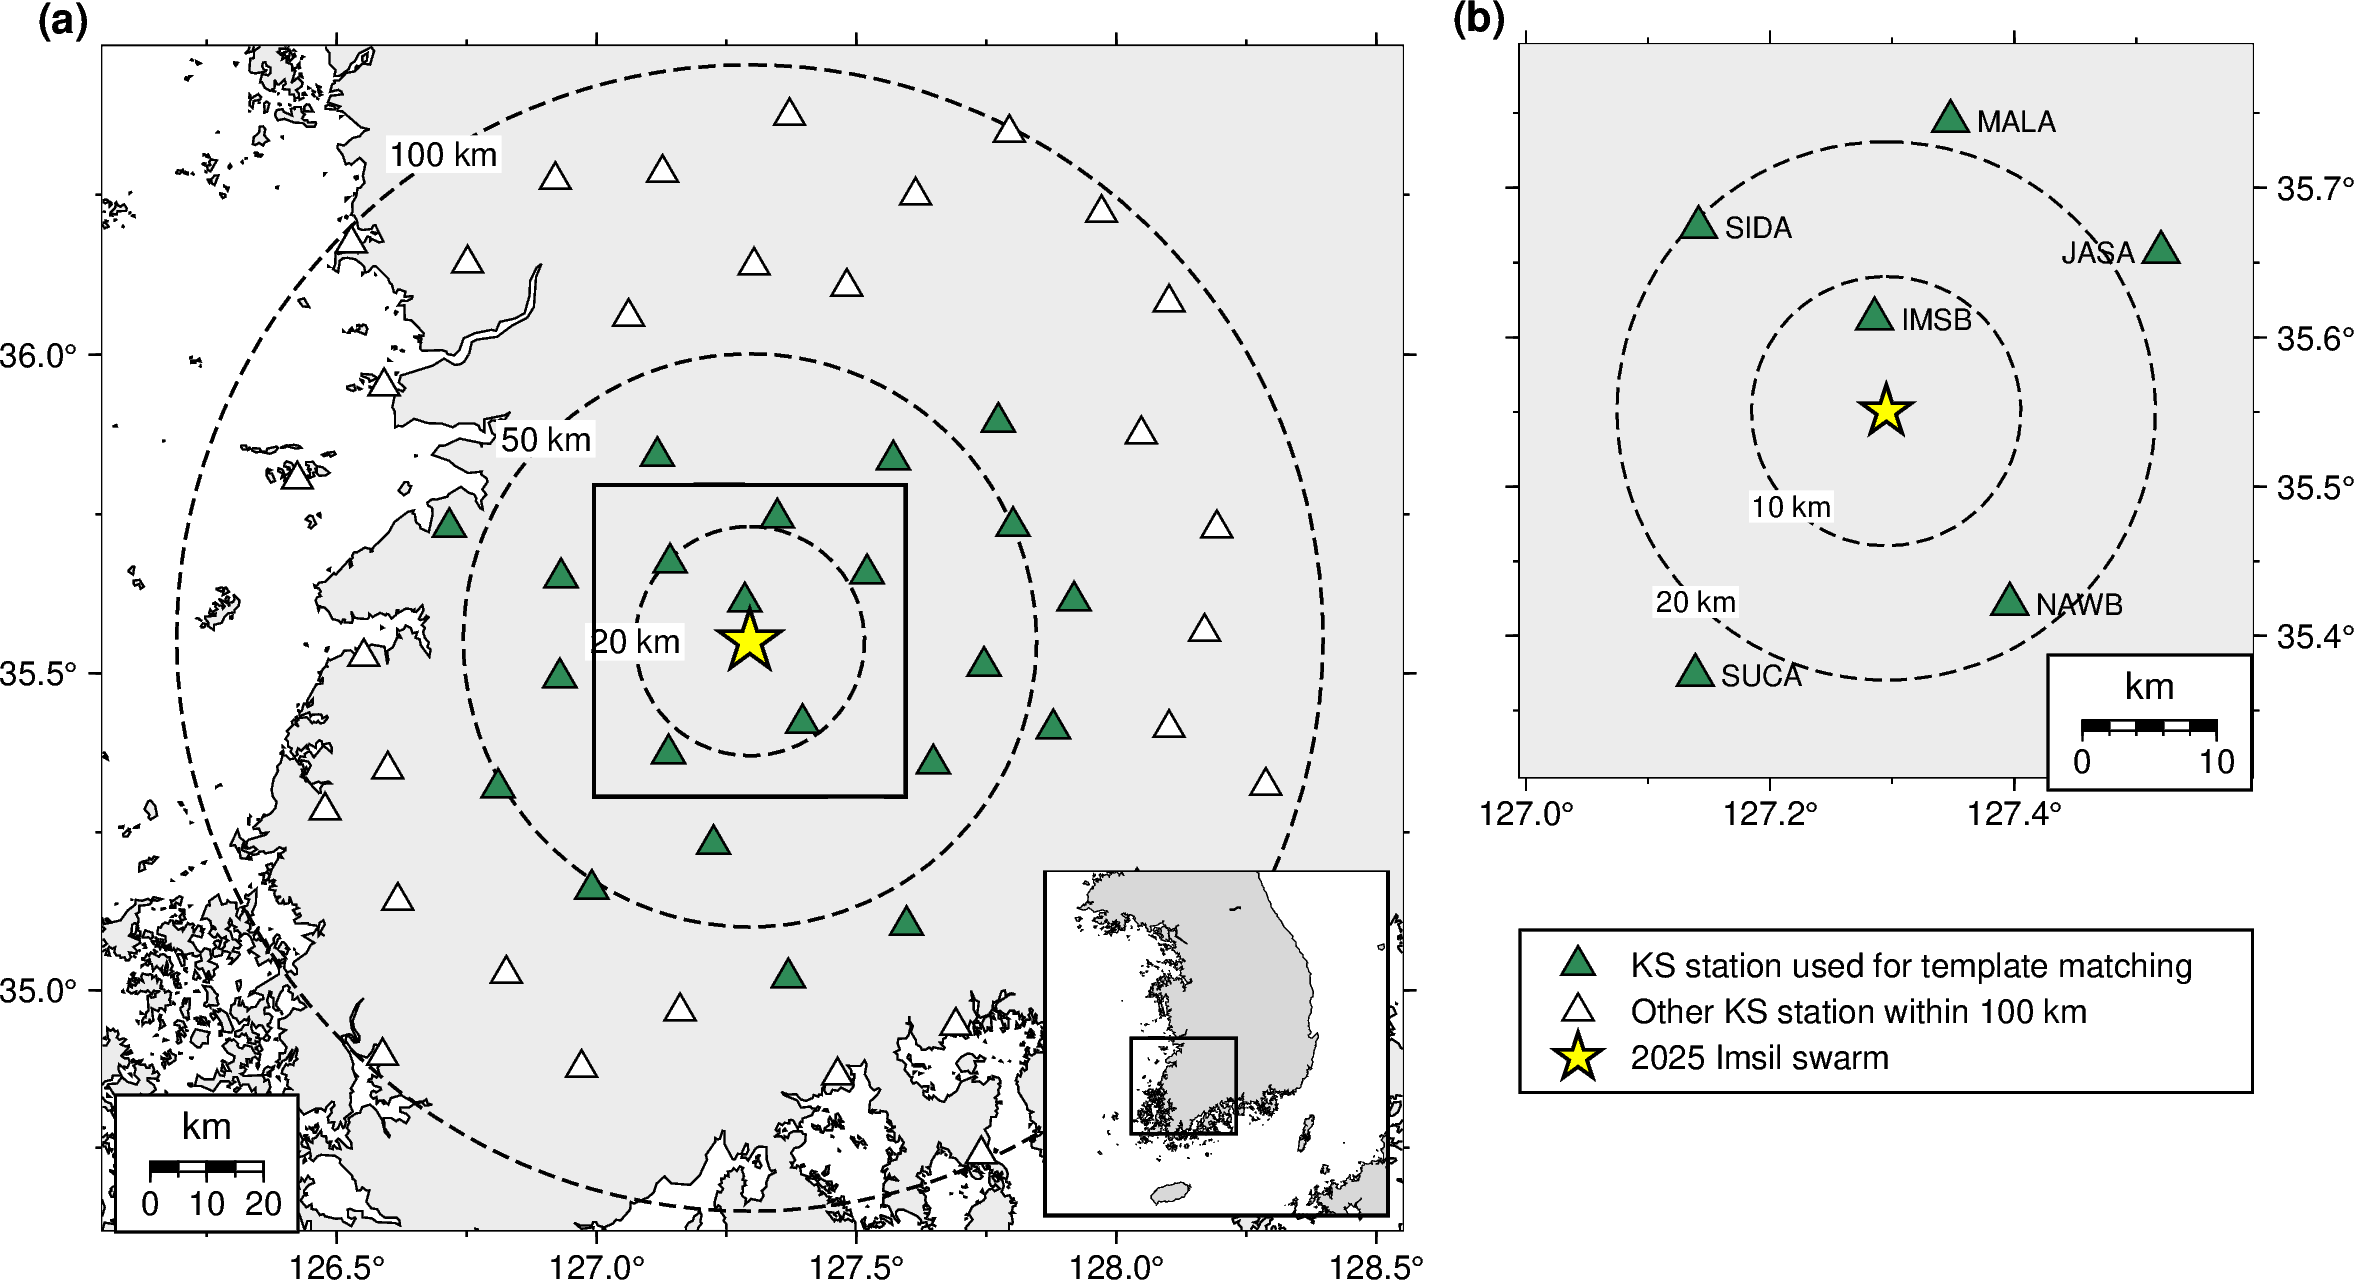

stations in panel b: IMSB 6.9 km, NAWB 17.0 km, SIDA 19.5 km, MALA 22.0 km, JASA 23.6 km, SUCA 24.2 km


In [5]:
import pygmt
from pyproj import Geod
g = Geod(ellps='WGS84'); lat0, lon0 = SRC
_, _, d_ = g.inv(np.full(len(STA), lon0), np.full(len(STA), lat0), STA.Longitude.to_numpy(), STA.Latitude.to_numpy()); STA['dist_km'] = d_ / 1e3
STA['fmf'] = STA.Code.isin(FMFSTA.station)
fact('data.nearest', f'{STA.sort_values("dist_km").Code.iloc[0]} ({STA.dist_km.min():.1f} km)', 'station_table/stations.csv')
fact('data.fmf_maxd', f'{STA[STA.fmf].dist_km.max():.0f}', 'station_table/stations.csv', 'farthest FMF station (km)')
def ring(radius_km, n=361):
    az = np.linspace(0, 360, n); lon, lat, _ = g.fwd(np.full(n, lon0), np.full(n, lat0), az, np.full(n, radius_km * 1e3)); return lon, lat
fmf_c, ks_c, src_c, land = '#2e8b57', 'white', 'yellow', '#ececec'
pygmt.config(FORMAT_GEO_MAP='ddd.x', MAP_FRAME_TYPE='plain', FONT_ANNOT_PRIMARY='8p,Helvetica', FONT_LABEL='9p,Helvetica', FONT_TITLE='9p,Helvetica', MAP_FRAME_PEN='0.8p', MAP_TICK_LENGTH_PRIMARY='0.12c')
fig = pygmt.Figure()
region = [126.05, 128.55, 34.62, 36.48]
fig.basemap(region=region, projection='M11c', frame=['WSen', 'xa0.5f0.25', 'ya0.5f0.25'])
fig.coast(shorelines='0.4p,black', land=land, water='white', resolution='h')
for r_km in (20, 50, 100):
    lon, lat = ring(r_km); fig.plot(x=lon, y=lat, pen='0.7p,black,4_2')
    lx, ly, _ = g.fwd(lon0, lat0, {20: 270.0, 50: 315.0, 100: 328.0}[r_km], r_km * 1e3); fig.text(x=lx, y=ly, text=f'{r_km} km', font='8p,Helvetica,black', justify='CM', fill='white', clearance='0.05c/0.05c')
o, f_ = STA[~STA.fmf], STA[STA.fmf]
fig.plot(x=o.Longitude, y=o.Latitude, style='t0.30c', fill=ks_c, pen='0.5p,black')
fig.plot(x=f_.Longitude, y=f_.Latitude, style='t0.32c', fill=fmf_c, pen='0.5p,black')
fig.plot(x=[lon0], y=[lat0], style='a0.55c', fill=src_c, pen='0.8p,black')
zoom = [lon0 - 0.30, lon0 + 0.30, lat0 - 0.245, lat0 + 0.245]
fig.plot(x=[zoom[0], zoom[1], zoom[1], zoom[0], zoom[0]], y=[zoom[2], zoom[2], zoom[3], zoom[3], zoom[2]], pen='0.9p,black')
fig.basemap(map_scale='jBL+w20k+f+o0.4c/0.4c+lkm', box='+gwhite+p0.6p,black')
with fig.inset(position='jBR+w2.9c+o0.12c/0.12c', box='+gwhite+p1.0p,black'):
    fig.coast(region=[124.0, 131.0, 33.0, 39.6], projection='M2.9c', land='#d8d8d8', water='white', shorelines='0.2p,black', resolution='i', frame=['nsew'])
    fig.plot(x=[region[0], region[1], region[1], region[0], region[0]], y=[region[2], region[2], region[3], region[3], region[2]], pen='0.8p,black')
fig.text(position='TL', text='(a)', font='10p,Helvetica-Bold', justify='BR', offset='-0.12c/0.12c', no_clip=True)
merc = lambda lat: np.log(np.tan(np.pi / 4 + np.radians(lat) / 2))
h_a = 11.0 * (merc(region[3]) - merc(region[2])) / np.radians(region[1] - region[0]); h_b = 6.2 * (merc(zoom[3]) - merc(zoom[2])) / np.radians(zoom[1] - zoom[0])
fig.shift_origin(xshift='12.0c', yshift=f'{h_a - h_b:.3f}c')
fig.basemap(region=zoom, projection='M6.2c', frame=['wSEn', 'xa0.2f0.1', 'ya0.1f0.05'])
fig.coast(shorelines='0.4p,black', land=land, water='white', resolution='f')
for r_km in (10, 20):
    lon, lat = ring(r_km); fig.plot(x=lon, y=lat, pen='0.6p,black,4_2')
    lx, ly, _ = g.fwd(lon0, lat0, 225.0, r_km * 1e3); fig.text(x=lx, y=ly, text=f'{r_km} km', font='7p,Helvetica,black', justify='CM', fill='white', clearance='0.04c/0.04c')
inz = STA[STA.Longitude.between(zoom[0], zoom[1]) & STA.Latitude.between(zoom[2], zoom[3])]
for sub, fill in ((inz[~inz.fmf], ks_c), (inz[inz.fmf], fmf_c)):
    if len(sub): fig.plot(x=sub.Longitude, y=sub.Latitude, style='t0.36c', fill=fill, pen='0.5p,black')
for r in inz.itertuples():
    right = r.Longitude > zoom[1] - 0.09
    fig.text(x=r.Longitude, y=r.Latitude, text=r.Code, font='7p,Helvetica,black', justify='MR' if right else 'ML', offset='-0.22c/0c' if right else '0.22c/0c')
fig.plot(x=[lon0], y=[lat0], style='a0.45c', fill=src_c, pen='0.8p,black')
fig.basemap(map_scale='jBR+w10k+f+o0.3c/0.3c+lkm', box='+gwhite+p0.6p,black')
fig.text(position='TL', text='(b)', font='10p,Helvetica-Bold', justify='BR', offset='-0.12c/0.12c', no_clip=True)
with tempfile.TemporaryDirectory() as tmp:
    spec = os.path.join(tmp, 'legend.txt')
    open(spec, 'w').write(f'S 0.35c t 0.32c {fmf_c} 0.5p,black 0.8c KS station used for template matching\nG 0.08c\n'
                          f'S 0.35c t 0.30c {ks_c} 0.5p,black 0.8c Other KS station within 100 km\nG 0.08c\n'
                          f'S 0.35c a 0.42c {src_c} 0.8p,black 0.8c 2025 Imsil swarm\n')
    fig.legend(spec=spec, position='x0c/-1.3c+w6.2c+jTL', box='+gwhite+p0.6p,black')
fig.savefig(f'{FIG}/Figure_01_station_map.pdf'); fig.savefig(f'{FIG}/Figure_01_station_map.png', dpi=DPI)
record('Figure_01_station_map', f'{DL}/station_table/stations.csv', f'{DL}/fmf_aligned/stations_imsil_5_20H.csv')
fig.show(width=900)
print('stations in panel b:', ', '.join(f'{r.Code} {r.dist_km:.1f} km' for r in inz.sort_values('dist_km').itertuples()))

## Figure 2: the swarm in time

Size is the 5–20 Hz S-wave peak-displacement ratio to the ML 1.9 (the E3 estimator of notebook 12: median over the channels on which the ML 1.9 has signal-to-noise ≥ 300; the instrument response cancels). The code is notebook 12's, verbatim. The right axis converts the ratio with the scale of Park et al. (2026), M = 2.07 + 0.73 log r + 0.23, which notebook 12 reproduced to 0.11 rms on their quoted events.

In [6]:
fmf = FMF.copy()
PARK = dict(c1=2.07, c2=0.73, band_amp=(5, 20), win_s=(-0.5, 2.0))
MW_OFF = 2.3 - PARK['c1']                                   # their Table 1: the ML 1.9 has Mw 2.3 (ratio 1)
REF_ID = '20251102203835'; REF_DIR = f'{DL}/runs/hypodd_dl/waveforms_100km/{REF_ID}'; MAXD = 80.0
o_ref = UTCDateTime(fmf.origin[(fmf.origin - pd.Timestamp('2025-11-02 20:38:35.4')).abs().idxmin()].to_pydatetime())
IREF = int((fmf.origin - pd.Timestamp(str(o_ref)[:23])).abs().idxmin())
picks = {}
for f in sorted(glob.glob(f'{REF_DIR}/*.sac')):
    s = obspy.read(f, headonly=True)[0].stats; h = s.sac
    ref = UTCDateTime(year=h.nzyear, julday=h.nzjday, hour=h.nzhour, minute=h.nzmin, second=h.nzsec, microsecond=int(h.nzmsec) * 1000)
    d = picks.setdefault(s.station, dict(net=s.network, prefix=s.channel[:2], dist=float(h.dist), lat=float(h.stla), lon=float(h.stlo), comps=set()))
    d['comps'].add(s.channel[2])
    if h.get('a', -12345) > -1e4: d['P'] = ref + float(h.a)
    if h.get('t0', -12345) > -1e4: d['S'] = ref + float(h.t0)

def load_band(net, sta, prefix, comp, band, n_int, days=(306, 307)):
    st = obspy.Stream()
    for jd in days:
        for f in glob.glob(f'{config.CONTINUOUS}/{net}/{sta}/{prefix}{comp}.D/*.D.2025.{jd:03d}'): st += obspy.read(f)
    if not len(st): return None
    for x in st:
        x.data = x.data.astype(np.float64)
        if abs(x.stats.sampling_rate - 100.0) > 1e-6: x.detrend('linear'); x.resample(100.0)
    st.merge(method=1, fill_value=0); tr = st[0]
    tr.detrend('linear'); tr.taper(0.001); tr.filter('bandpass', freqmin=band[0], freqmax=band[1], corners=4, zerophase=True)
    for _ in range(n_int):
        tr.integrate(); tr.filter('bandpass', freqmin=band[0], freqmax=band[1], corners=4, zerophase=True)
    return tr

def peak(tr, a, b):
    t0, fs, d = tr.stats.starttime, tr.stats.sampling_rate, tr.data
    i, j = int(round((a - t0) * fs)), int(round((b - t0) * fs))
    if i < 0 or j > len(d) or j <= i: return np.nan
    w = d[i:j]; return float(np.abs(w).max()) if np.any(w) else np.nan

t_ev = [UTCDateTime(t.to_pydatetime()) for t in fmf.origin]; tic = time.time()
use_sta = {k: v for k, v in picks.items() if 'P' in v and 'S' in v and v['dist'] <= MAXD}
A, NZ, KEYS, KDIST = [], [], [], []
for sta, v in sorted(use_sta.items()):
    for comp in sorted(v['comps']):
        tr = load_band(v['net'], sta, v['prefix'], comp, PARK['band_amp'], 2 if v['prefix'] == 'HG' else 1)
        if tr is None: continue
        A.append([peak(tr, v['S'] + (te - o_ref) + PARK['win_s'][0], v['S'] + (te - o_ref) + PARK['win_s'][1]) for te in t_ev])
        NZ.append([peak(tr, v['P'] + (te - o_ref) - 2.5, v['P'] + (te - o_ref) - 0.5) for te in t_ev])
        KEYS.append((sta, comp)); KDIST.append(v['dist'])
A, NZ, KDIST = np.array(A), np.array(NZ), np.array(KDIST)
Ar = A[:, IREF]; SNR_REF = Ar / NZ[:, IREF]
use3 = (SNR_REF >= 300) & np.isfinite(A).all(1)
lr3 = np.median(np.log10(A[use3] / Ar[use3, None]), axis=0)
floor_lr = np.median(np.log10(NZ[use3] / Ar[use3, None]), axis=0)
fmf['lr'], fmf['floor_lr'] = lr3, floor_lr
print(f'{len(KEYS)} channels read; E3 on {use3.sum()} channels; {time.time() - tic:.0f} s')

108 channels read; E3 on 8 channels; 332 s


findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.


findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive


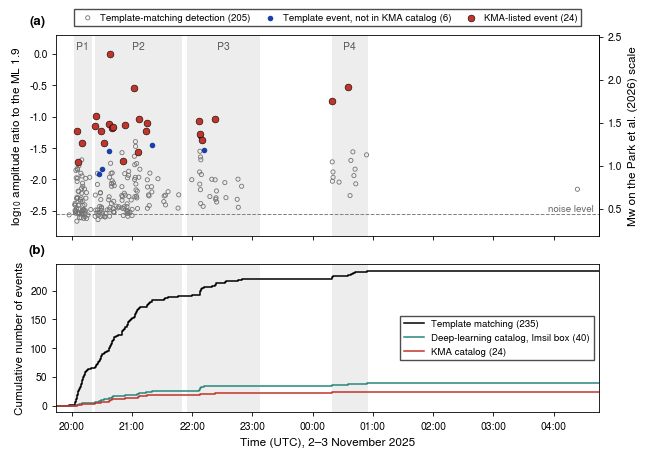

E3 range -2.67 to 0.00; median noise reading -2.55


In [7]:
mw_of = lambda lr: PARK['c1'] + PARK['c2'] * lr + MW_OFF; lr_of = lambda mw: (mw - PARK['c1'] - MW_OFF) / PARK['c2']
PH = [('P1', '2025-11-02 20:02', '2025-11-02 20:19:59'), ('P2', '2025-11-02 20:23', '2025-11-02 21:49:59'), ('P3', '2025-11-02 21:55', '2025-11-02 23:07:59'), ('P4', '2025-11-03 00:19', '2025-11-03 00:54:59')]
kma_t = KMA.origin_time_UTC.to_numpy()
near_kma = [int((fmf.origin - t).abs().idxmin()) for t in KMA.origin_time_UTC]
dt_kma = np.array([abs((fmf.origin[i] - t).total_seconds()) for i, t in zip(near_kma, KMA.origin_time_UTC)])
assert len(set(near_kma)) == len(KMA) and dt_kma.max() <= 12, (len(set(near_kma)), dt_kma.max())
fmf['kma'] = fmf.index.isin(near_kma)
box = DLC[DLC.in_imsil_box & (DLC.time >= '2025-11-02 19:30') & (DLC.time <= '2025-11-03 05:00')].sort_values('time')
fig, ax = plt.subplots(2, 1, figsize=(7.0, 4.9), sharex=True, gridspec_kw=dict(height_ratios=[1.35, 1], hspace=0.16))
for a in ax:
    for lab, t0, t1 in PH:
        a.axvspan(pd.Timestamp(t0), pd.Timestamp(t1), color='0.93', lw=0, zorder=0)
for lab, t0, t1 in PH: ax[0].text(pd.Timestamp(t0) + (pd.Timestamp(t1) - pd.Timestamp(t0)) / 2, 0.97, lab, transform=ax[0].get_xaxis_transform(), ha='center', va='top', fontsize=7.5, color='0.35')
nw = fmf[~fmf.is_reference & ~fmf.kma]; rf = fmf[fmf.is_reference & ~fmf.kma]; km = fmf[fmf.kma]
ax[0].scatter(nw.origin, nw.lr, s=9, facecolor='none', edgecolor='0.45', lw=0.6, label=f'Template-matching detection ({len(nw)})', zorder=2)
ax[0].scatter(rf.origin, rf.lr, s=16, color='#1b3fa8', lw=0, label=f'Template event, not in KMA catalog ({len(rf)})', zorder=3)
ax[0].scatter(km.origin, km.lr, s=24, color='#c1352b', edgecolor='black', lw=0.4, label=f'KMA-listed event ({len(km)})', zorder=4)
fl = np.median(fmf.floor_lr); ax[0].axhline(fl, color='0.5', lw=0.7, ls='--', zorder=1); ax[0].text(pd.Timestamp('2025-11-03 04:40'), fl, 'noise level', fontsize=7, color='0.4', va='bottom', ha='right')
ax[0].set_ylabel('log$_{10}$ amplitude ratio to the ML 1.9'); ax[0].set_ylim(-2.9, 0.3)
sec = ax[0].secondary_yaxis('right', functions=(mw_of, lr_of)); sec.set_ylabel('Mw on the Park et al. (2026) scale')
ax[0].legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=3, frameon=True, fontsize=7, handletextpad=0.3, columnspacing=1.0)
for frame, col, lab in ((fmf.origin, 'black', f'Template matching ({len(fmf)})'), (box.time, '#28867c', f'Deep-learning catalog, Imsil box ({len(box)})'), (KMA.origin_time_UTC.sort_values(), '#c1352b', f'KMA catalog ({len(KMA)})')):
    t = pd.Series(sorted(frame)); ax[1].step(pd.concat([pd.Series([pd.Timestamp('2025-11-02 19:45')]), t, pd.Series([pd.Timestamp('2025-11-03 04:45')])]),
                                          np.r_[0, np.arange(1, len(t) + 1), len(t)], where='post', color=col, lw=1.1, label=lab)
ax[1].set_ylabel('Cumulative number of events'); ax[1].legend(loc='center right', frameon=True, fontsize=7)
ax[1].set_xlim(pd.Timestamp('2025-11-02 19:45'), pd.Timestamp('2025-11-03 04:45')); ax[1].xaxis.set_major_formatter(mdates.DateFormatter('%H:%M')); ax[1].xaxis.set_major_locator(mdates.HourLocator())
ax[1].set_xlabel('Time (UTC), 2–3 November 2025')
letter(ax[0], 'a'); letter(ax[1], 'b')
save(fig, 'Figure_02_swarm_timeline'); record('Figure_02_swarm_timeline', f'{DL}/catalogs/fmf_final/imsil_fmf_catalog.csv', f'{DL}/catalogs/imsil_dl_catalog.csv', f'{DL}/catalogs/imsil_kma24.csv')
fact('t.first', fmf.origin.min().strftime('%H:%M:%S'), 'catalogs/fmf_final'); fact('t.last_window', fmf.origin[win].max().strftime('%H:%M:%S'), 'catalogs/fmf_final')
fact('t.box_swarm', len(box), 'catalogs/imsil_dl_catalog.csv', 'in-box DL events 19:30-05:00 UTC')
fact('mag.n_above_floor', int((fmf.lr > fmf.floor_lr + 0.3).sum()), 'this notebook (E3)', 'detections whose E3 ratio exceeds the pre-P noise reading by more than 0.3 log units')
fact('t.span_h', f'{(fmf.origin[win].max() - fmf.origin.min()).total_seconds() / 3600:.0f}', 'catalogs/fmf_final', 'hours from the first detection to the last in the window, rounded'); fact('mag.n_noise', int(len(fmf) - (fmf.lr > fmf.floor_lr + 0.3).sum()), 'this notebook (E3)', 'ratio within 0.3 log units of its own pre-P noise reading'); fact('mag.mw_ref', f'{mw_of(0):.1f}', 'Park scale'); fact('mag.mw_min', f'{mw_of(fmf.lr.min()):.1f}', 'this notebook (E3)')
print(f'E3 range {fmf.lr.min():.2f} to {fmf.lr.max():.2f}; median noise reading {fl:.2f}')

## Figure 3: geometry of the 101 events that meet the 25 m rule

The plane is Haenam's SVD fit (verbatim, as in notebooks 04, 10 and 11). Positions are relative to the centroid: the absolute depth of a double-difference cluster is not resolved (notebook 12), so depths are shown relative to it.

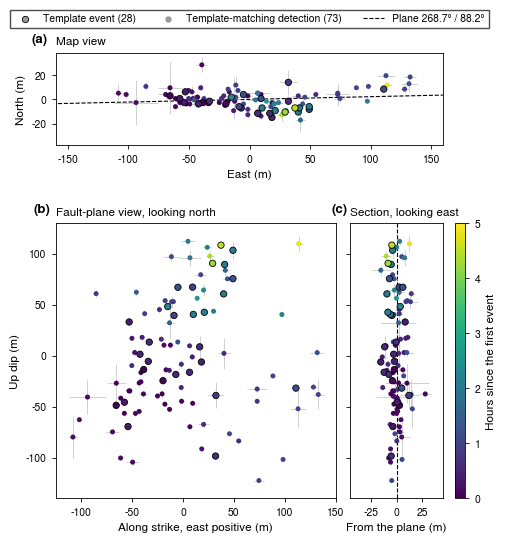

plane 268.7/88.2, dipping north; RMS 7.4 m; 99 % within 15 m; first event 2025-11-02 20:03:28.800000


In [8]:
def plane(X):
    center=np.mean(X,axis=0);_,sv,v=np.linalg.svd(X-center,full_matrices=False);n=v[-1]
    if n[2]>0:n=-n
    dip=np.degrees(np.arccos(np.clip(-n[2],-1,1)));strike=(np.degrees(np.arctan2(n[0],n[1]))-90)%360
    s=np.array([np.sin(np.radians(strike)),np.cos(np.radians(strike)),0]);h=np.array([np.cos(np.radians(strike)),-np.sin(np.radians(strike)),0]);down=h*np.cos(np.radians(dip))+np.array([0,0,np.sin(np.radians(dip))])
    return dict(center=center,normal=n,strike=strike,dip=dip,s=s,h=h,down=down,rms=float(np.sqrt(np.mean(((X-center)@n)**2))),sv=sv)
ev = R25.sort_values('time').reset_index(drop=True)
la0, lo0 = ev.latitude.mean(), ev.longitude.mean()
ev['E'] = (ev.longitude - lo0) * 111.19 * np.cos(np.radians(la0)) * 1000; ev['N'] = (ev.latitude - la0) * 111.19 * 1000; ev['D'] = (ev.depth_km - ev.depth_km.mean()) * 1000
P = plane(ev[['E', 'N', 'D']].to_numpy()); STRIKE, DIP = P['strike'], P['dip']
us = P['s'] if P['s'][0] > 0 else -P['s']; nv = P['normal'] if P['normal'][1] > 0 else -P['normal']
X = ev[['E', 'N', 'D']].to_numpy() - P['center']; ev['along'], ev['up'], ev['nrm'] = X @ us, -(X @ P['down']), X @ nv
ev['hours'] = (ev.time - ev.time.min()).dt.total_seconds() / 3600
fact('geo.strike', f'{STRIKE:.1f}', 'this notebook (plane of reference_25m_fmf)'); fact('geo.dip', f'{DIP:.1f}', 'this notebook'); fact('geo.rms', f'{P["rms"]:.1f}', 'this notebook', 'RMS distance from the plane (m)')
fact('geo.n99', f'{np.percentile(np.abs(ev.nrm), 99):.0f}', 'this notebook', '99th percentile of |distance from the plane| (m)')
fact('geo.len', f'{ev.along.max() - ev.along.min():.0f}', 'this notebook', 'full along-strike range (m)'); fact('geo.hgt', f'{ev.up.max() - ev.up.min():.0f}', 'this notebook', 'full up-dip range (m)')
dip_dir = 'north' if nv[2] < 0 else 'south'
cm = plt.get_cmap('viridis'); norm = mpl.colors.Normalize(0, np.ceil(ev.hours.max()))
XR_B, YR, XR_C, XR_A, YR_A = (-125, 150), (-140, 130), (-46, 46), (-160, 160), (-38, 38)
H_B = 2.75; W_B = H_B * np.ptp(XR_B) / np.ptp(YR); W_C = H_B * np.ptp(XR_C) / np.ptp(YR); L0, B0, GAP = 0.62, 0.52, 0.14
W_A = W_B + GAP + W_C; H_A = W_A * np.ptp(YR_A) / np.ptp(XR_A); FW, FH = L0 + W_B + GAP + W_C + 1.0, B0 + H_B + 0.78 + H_A + 0.62
fig = plt.figure(figsize=(FW, FH)); axin = lambda l, b, w, h: fig.add_axes([l / FW, b / FH, w / FW, h / FH])
ax = [axin(L0, B0 + H_B + 0.78, W_A, H_A), axin(L0, B0, W_B, H_B)]; ax.append(axin(L0 + W_B + GAP, B0, W_C, H_B)); ax[2].sharey(ax[1])
cax = axin(L0 + W_B + GAP + W_C + 0.12, B0, 0.1, H_B)
views = ((ax[0], 'E', 'N', 'ex95_m', 'ey95_m', 'East (m)', 'North (m)', XR_A, YR_A),
         (ax[1], 'along', 'up', 'ex95_m', 'ez95_m', 'Along strike, east positive (m)', 'Up dip (m)', XR_B, YR),
         (ax[2], 'nrm', 'up', 'ey95_m', 'ez95_m', 'From the plane (m)', '', XR_C, YR))
kind_ref = ev.kind == 'reference'
for a, x, y, exc, eyc, xl, yl, xr, yr in views:
    a.errorbar(ev[x], ev[y], xerr=ev[exc], yerr=ev[eyc], fmt='none', ecolor='0.75', elinewidth=0.5, zorder=1)
    a.scatter(ev[x][~kind_ref], ev[y][~kind_ref], c=ev.hours[~kind_ref], cmap=cm, norm=norm, s=13, edgecolor='none', zorder=2)
    a.scatter(ev[x][kind_ref], ev[y][kind_ref], c=ev.hours[kind_ref], cmap=cm, norm=norm, s=21, edgecolor='black', lw=0.6, zorder=3)
    a.set_xlim(*xr); a.set_ylim(*yr); a.set_aspect('equal', adjustable='box'); a.set_xlabel(xl); a.set_ylabel(yl)
plt.setp(ax[2].get_yticklabels(), visible=False)
t_ = np.linspace(-200, 200, 2); ax[0].plot(P['center'][0] + t_ * P['s'][0], P['center'][1] + t_ * P['s'][1], 'k--', lw=0.8, zorder=0)
ax[2].axvline(0, color='k', ls='--', lw=0.8, zorder=0)
ax[0].set_title('Map view', loc='left'); ax[1].set_title('Fault-plane view, looking north', loc='left'); ax[2].set_title('Section, looking east', loc='left')
for a, s_ in zip(ax, 'abc'): letter(a, s_)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cm); cb = fig.colorbar(sm, cax=cax); cb.set_label('Hours since the first event')
ax[0].scatter([], [], s=21, facecolor='0.6', edgecolor='black', lw=0.6, label=f'Template event ({int(kind_ref.sum())})'); ax[0].scatter([], [], s=13, color='0.6', label=f'Template-matching detection ({int((~kind_ref).sum())})')
ax[0].plot([], [], 'k--', lw=0.8, label=f'Plane {STRIKE:.1f}° / {DIP:.1f}°')
ax[0].legend(loc='lower center', bbox_to_anchor=(0.5, 1.22), ncol=3, frameon=True)
save(fig, 'Figure_03_geometry'); record('Figure_03_geometry', f'{DL}/catalogs/reference_25m_fmf/DL_reference_25m.csv')
print(f'plane {STRIKE:.1f}/{DIP:.1f}, dipping {dip_dir}; RMS {P["rms"]:.1f} m; 99 % within {np.percentile(np.abs(ev.nrm), 99):.0f} m; first event {ev.time.min()}')

## Figure 4: migration

The functions are notebook 11's, verbatim. The front-fit window is decision D24 (open), so the figure shows the 0.5, 1 and 2 h windows. The back front is not shown: notebook 11 found it unstable.

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


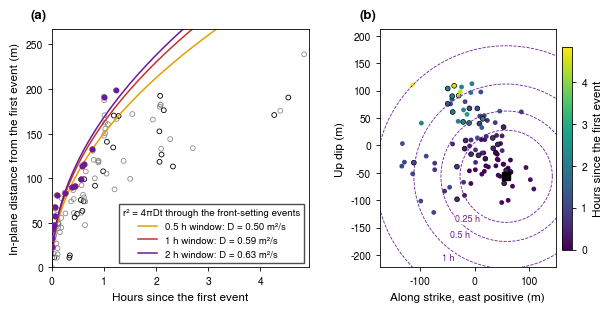

,window_h,D_m2_s,LS_ci95,boot_lo,boot_hi,n_front,n_window
0.50,0.5,0.499736,0.174412,0.418355,0.742956,10,41
1.00,1.0,0.585742,0.103849,0.421385,0.674034,15,65
2.00,2.0,0.626715,0.087753,0.482876,0.685712,16,84
4.84,4.84,0.320654,0.079411,0.274305,0.667317,17,100


In [9]:
cen = P['center']; phi, dl_ = np.radians(STRIKE), np.radians(DIP)
u_s = np.array([np.sin(phi), np.cos(phi), 0.0]); u_d = np.array([np.cos(phi) * np.cos(dl_), -np.sin(phi) * np.cos(dl_), np.sin(dl_)]); n_v = np.cross(u_s, u_d)
Rr = ev[['E', 'N', 'D']].to_numpy() - cen; Rp = Rr - np.outer(Rr @ n_v, n_v)
ev['along11'], ev['down_dip'] = Rp @ u_s, Rp @ u_d
first = ev.iloc[0]
ev['ts'] = (ev.time - first.time).dt.total_seconds() / 86400.0
ev['r'] = np.hypot(ev.along11 - first.along11, ev.down_dip - first.down_dip)
def front_fit(ts, r):
    "record-breaking events within the fit window -> D (m^2/s) through the origin, its LS standard error, the front indices"
    w = (ts > 0) & (ts <= FIT_D)
    o = np.argsort(ts[w]); tw, rw = ts[w][o], r[w][o]
    isf = rw >= np.maximum.accumulate(rw)
    tf, rf = tw[isf], rw[isf]; X = 4 * np.pi * tf * 86400.0
    Dv = float((X * rf ** 2).sum() / (X ** 2).sum())
    se = float(np.sqrt(((rf ** 2 - X * Dv) ** 2).sum() / max(len(tf) - 1, 1) / (X ** 2).sum()))
    return Dv, se, np.flatnonzero(w)[o][isf]
NBOOT = 2000; rng = np.random.default_rng(7); ts, r = ev.ts.to_numpy(), ev.r.to_numpy(); FRONT = {}
for hours in (0.5, 1.0, 2.0, 4.84):
    FIT_D = hours / 24.0
    Dv, se, idx = front_fit(ts, r); w = np.flatnonzero((ts > 0) & (ts <= FIT_D))
    Db = np.asarray([front_fit(ts[k], r[k])[0] for k in (rng.choice(w, len(w), replace=True) for _ in range(NBOOT))])
    ci95 = float(sps.t.ppf(0.975, max(len(idx) - 1, 1)) * se)
    FRONT[hours] = dict(window_h=hours, D_m2_s=Dv, LS_ci95=ci95, boot_lo=np.percentile(Db, 2.5), boot_hi=np.percentile(Db, 97.5), n_front=len(idx), n_window=len(w), idx=idx)
for h_, k_ in ((0.5, '05'), (1.0, '1'), (2.0, '2')):
    Fh = FRONT[h_]; q11 = grab('11_migration_diffusion_backfront.ipynb', rf'Triggering front D, {h_:g} h window \(LS 95 %; boo[^\n]*?([\d.]+) m²/s')
    assert q11 == f'{Fh["D_m2_s"]:.3f}', (h_, q11, Fh['D_m2_s'])
    fact(f'mig.D{k_}', f'{Fh["D_m2_s"]:.2f}', 'this notebook = notebooks/11 (asserted)', f'{h_:g} h window'); fact(f'mig.D{k_}_ci', f'{Fh["boot_lo"]:.2f}–{Fh["boot_hi"]:.2f}', 'this notebook', 'bootstrap 95 %')
quote('mig.bf_t0', '11_migration_diffusion_backfront.ipynb', r't0 = ([\d.]+) min, D = [\d.]+ m2/s; stratified'); quote('mig.bf_t0_ci', '11_migration_diffusion_backfront.ipynb', r'stratified resamples \(300\): t0 ([\d.]+-[\d.]+) min', lambda v: v.replace('-', '–'))
quote('mig.bf_in', '11_migration_diffusion_backfront.ipynb', r'events after t0 inside the fitted back front: (\d+ of \d+)')
cols = {0.5: '#e69f00', 1.0: '#c1352b', 2.0: '#6a1b9a'}
fig, ax = plt.subplots(1, 2, figsize=(7.0, 3.1), gridspec_kw=dict(width_ratios=[1.2, 1], wspace=0.3))
ax[0].scatter(ev.ts * 24, ev.r, s=12, facecolor='none', edgecolor=np.where(ev.kind == 'reference', 'black', '0.55'), lw=0.6, zorder=2)
for h_ in (0.5, 1.0, 2.0):
    Fh = FRONT[h_]; tt = np.linspace(0, ev.ts.max() * 24, 300)
    ax[0].plot(tt, np.sqrt(4 * np.pi * Fh['D_m2_s'] * tt * 3600), color=cols[h_], lw=1.1, label=f'{h_:g} h window: D = {Fh["D_m2_s"]:.2f} m²/s')
    ax[0].scatter(ev.ts.iloc[Fh['idx']] * 24, ev.r.iloc[Fh['idx']], s=10, color=cols[h_], zorder=3)
ax[0].set_xlabel('Hours since the first event'); ax[0].set_ylabel('In-plane distance from the first event (m)'); ax[0].set_ylim(0, ev.r.max() * 1.12); ax[0].set_xlim(0, ev.ts.max() * 24 * 1.02)
ax[0].legend(loc='lower right', frameon=True, fontsize=7, title='r² = 4πDt through the front-setting events', title_fontsize=7)
F2 = FRONT[2.0]
sc = ax[1].scatter(ev.along11, -ev.down_dip, c=ev.ts * 24, cmap='viridis', s=12, edgecolor=np.where(ev.kind == 'reference', 'black', 'none'), lw=0.5)
ax[1].plot(first.along11, -first.down_dip, 's', color='black', ms=6)
for hh in (0.25, 0.5, 1.0, 2.0):
    rr = np.sqrt(4 * np.pi * F2['D_m2_s'] * hh * 3600); ang = np.linspace(0, 2 * np.pi, 200)
    ax[1].plot(first.along11 + rr * np.cos(ang), -first.down_dip + rr * np.sin(ang), color=cols[2.0], lw=0.6, ls='--')
    ax[1].text(first.along11 + rr * np.cos(np.radians(236)), -first.down_dip + rr * np.sin(np.radians(236)), f'{hh:g} h', fontsize=6.5, color=cols[2.0], ha='right', va='top', clip_on=True,
               bbox=dict(facecolor='white', edgecolor='none', pad=0.3))
ax[1].set_aspect('equal', adjustable='datalim'); ax[1].set_xlabel('Along strike, east positive (m)'); ax[1].set_ylabel('Up dip (m)')
ax[1].set_xlim(ev.along11.min() - 40, ev.along11.max() + 40); ax[1].set_ylim(-ev.down_dip.max() - 40, -ev.down_dip.min() + 40)
cb = fig.colorbar(sc, ax=ax[1], shrink=0.85, pad=0.03); cb.set_label('Hours since the first event')
letter(ax[0], 'a'); letter(ax[1], 'b')
save(fig, 'Figure_04_migration'); record('Figure_04_migration', f'{DL}/catalogs/reference_25m_fmf/DL_reference_25m.csv')
display(pd.DataFrame(FRONT).T.drop(columns='idx').round(3))

## Figure 5: the long template-matching scan, 2018-01-01 to 2026-10-03

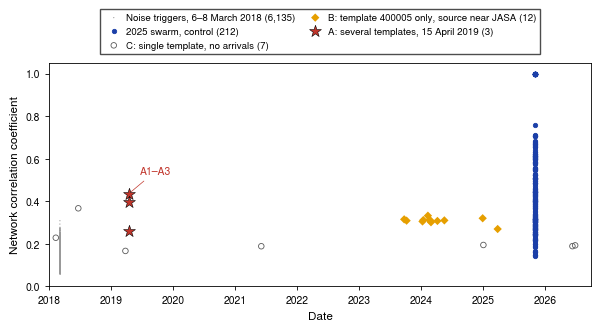

{'burst': 6135, 'swarm': 212, 'B': 12, 'C': 7, 'A': 3}


In [10]:
L = LONG.copy(); L['group'] = 'other'
inw = (L.origin >= '2025-11-02 19:30') & (L.origin <= '2025-11-03 05:00'); L.loc[inw, 'group'] = 'swarm'
burst = (L.origin >= '2018-03-06') & (L.origin < '2018-03-09'); L.loc[burst, 'group'] = 'burst'
lab_of = {}
for r_ in EVD[EVD.group.isin(['A', 'B', 'C'])].itertuples():
    i = (L.origin - r_.origin).abs().idxmin(); assert abs((L.origin[i] - r_.origin).total_seconds()) < 1; L.loc[i, 'group'] = r_.group; lab_of[i] = r_.label
assert (L.group == 'other').sum() == 0, (L.group == 'other').sum()
n = L.group.value_counts()
fact('long.n_days', '3,198', 'docs/decisions.csv D25'); assert '3,198/3,198 days' in DEC.loc['D25', 'effect_on_counts']
fact('long.n', f'{len(L):,}', 'long-scan catalog'); fact('long.n_swarm', int(n['swarm']), 'long-scan catalog'); fact('long.n_burst', f'{int(n["burst"]):,}', 'long-scan catalog')
fact('long.n_other', int(n.get('A', 0) + n.get('B', 0) + n.get('C', 0)), 'long-scan catalog'); fact('long.nA', int(n['A']), 'evidence'); fact('long.nB', int(n['B']), 'evidence'); fact('long.nC', int(n['C']), 'evidence')
fB = L[L.group == 'B'].origin; fact('long.B_first', fB.min().strftime('%B %Y'), 'long-scan catalog'); fact('long.B_last', fB.max().strftime('%B %Y'), 'long-scan catalog')
assert set(L[L.group == 'B'].template_cuspid) == {int(c5.index[0])}
fig, ax = plt.subplots(figsize=(7.0, 2.9))
ax.axvspan(pd.Timestamp('2018-03-06'), pd.Timestamp('2018-03-09'), color='0.85', lw=0, zorder=0)
sty = dict(burst=('.', '0.6', 3, f'Noise triggers, 6–8 March 2018 ({n["burst"]:,})'), swarm=('o', '#1b3fa8', 10, f'2025 swarm, control ({n["swarm"]})'),
           C=('o', '0.35', 16, f'C: single template, no arrivals ({n["C"]})'), B=('D', '#e69f00', 18, f'B: template {int(c5.index[0])} only, source near JASA ({n["B"]})'),
           A=('*', '#c1352b', 80, f'A: several templates, 15 April 2019 ({n["A"]})'))
for gname, (mk, col, sz, lab) in sty.items():
    q = L[L.group == gname]
    ax.scatter(q.origin, q.cc, marker=mk, s=sz, facecolor=col if gname not in ('C',) else 'none', edgecolor=col if gname in ('C', 'swarm') else ('black' if gname == 'A' else 'none'),
               lw=0.6 if gname != 'A' else 0.4, label=lab, zorder=4 if gname == 'A' else 3)
ax.set_ylabel('Network correlation coefficient'); ax.set_xlabel('Date'); ax.set_xlim(pd.Timestamp('2018-01-01'), pd.Timestamp('2026-10-03'))
ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.set_ylim(0, 1.05)
ax.annotate('A1–A3', (pd.Timestamp('2019-04-15'), L[L.group == 'A'].cc.max()), xytext=(8, 14), textcoords='offset points', fontsize=7.5, color='#c1352b', arrowprops=dict(arrowstyle='-', lw=0.5, color='#c1352b'))
ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=2, frameon=True, fontsize=7, handletextpad=0.3, columnspacing=1.0)
save(fig, 'Figure_05_long_scan'); record('Figure_05_long_scan', LONG_CSV, f'{DL}/catalogs/fmf_long_candidates_evidence.csv')
print(n.to_dict())

## Figure 6: waveforms of the 2019-04-15 events against their templates

For each event, its best template (the one whose detection defines the origin) is compared with the event at the stations that carry the template's S window. The traces are the 5–20 Hz band (zero-phase, 4 poles, as in the scan) and normalized per trace. The template is black and the 2019 event red. The number is the zero-lag correlation in the scan's window at the detection time: P 1.5 s on Z, S 2.0 s, both starting 0.5 s before the pick.

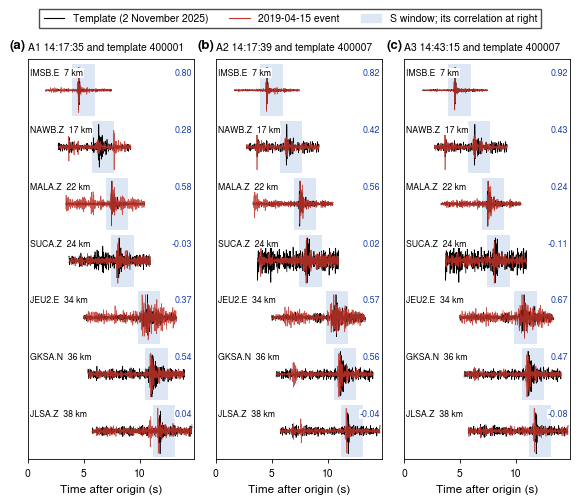

skipped channels: [('A1', 'SIDA', 'E', 'no data'), ('A1', 'SIDA', 'N', 'no data'), ('A2', 'SIDA', 'E', 'no data'), ('A2', 'SIDA', 'N', 'no data'), ('A3', 'SIDA', 'E', 'no data'), ('A3', 'SIDA', 'N', 'no data')]


,event,template,station,dist_km,comp,cc_S,cc_P
0,A1,400001,IMSB,7.18,E,0.80,NaN
1,A1,400001,NAWB,16.70,Z,0.28,-0.04
2,A1,400001,MALA,22.19,Z,0.58,-0.11
3,A1,400001,SUCA,24.23,Z,-0.03,-0.06
4,A1,400001,JEU2,33.99,E,0.37,NaN
5,A1,400001,GKSA,35.92,N,0.54,NaN
6,A1,400001,JLSA,38.18,Z,0.04,NaN
7,A2,400007,IMSB,7.22,E,0.82,0.25
8,A2,400007,NAWB,16.71,Z,0.42,0.28
9,A2,400007,MALA,22.27,Z,0.56,NaN


In [11]:
A_EV = pd.read_csv(f'{DL}/catalogs/fmf_long_2019A.csv', parse_dates=['origin']).sort_values('origin').reset_index(drop=True); A_EV['label'] = ['A1', 'A2', 'A3']
SHOW = 7
def day_trace(net, sta, comp, t0, t1):
    year, jd = t0.year, t0.julday
    for prefix in ('HH', 'EL', 'HG', 'BH'):
        fs = glob.glob(f'{config.CONTINUOUS}/{net}/{sta}/{prefix}{comp}.D/*.D.{year}.{jd:03d}')
        if not fs: continue
        st = obspy.read(fs[0], starttime=t0 - 30, endtime=t1 + 30)
        if not len(st): continue
        for x in st:
            x.data = x.data.astype(np.float64)
            if abs(x.stats.sampling_rate - 100.0) > 1e-6: x.detrend('linear'); x.resample(100.0)
        st.merge(method=1, fill_value=0); tr = st[0]; tr.detrend('linear'); tr.taper(0.05); tr.filter('bandpass', freqmin=5, freqmax=20, corners=4, zerophase=True)
        tr = tr.slice(t0, t1)
        return (tr, prefix) if len(tr.data) and np.any(tr.data) else (None, None)
    return None, None
def seg(tr, a, b):
    i = int(round((a - tr.stats.starttime) * 100)); j = i + int(round((b - a) * 100)); return tr.data[i:j] if i >= 0 and j <= len(tr.data) else None
def ncc(x, y): return float(np.dot(x - x.mean(), y - y.mean()) / np.sqrt(np.sum((x - x.mean()) ** 2) * np.sum((y - y.mean()) ** 2)))
SON_Z = set(LONGSTA.station[LONGSTA.horizontals == 0])
fig, axs = plt.subplots(1, 3, figsize=(7.0, 5.2), gridspec_kw=dict(wspace=0.13))
CCROWS = []; TRY = []
for a, ev_ in zip(axs, A_EV.itertuples()):
    tp = TPL.set_index('cuspid').loc[ev_.template_cuspid]; t_o = UTCDateTime(str(tp.origin_time_UTC)); d_o = UTCDateTime(ev_.origin.to_pydatetime())
    rows = []
    for f in sorted(glob.glob(f'{DL}/runs/hypodd_dl/waveforms_100km/{tp.event_id}/*Z.sac')):
        s_ = obspy.read(f, headonly=True)[0].stats; h = s_.sac
        if s_.station not in set(FMFSTA.station) or h.get('t0', -12345) < -1e4: continue
        refT = UTCDateTime(year=h.nzyear, julday=h.nzjday, hour=h.nzhour, minute=h.nzmin, second=h.nzsec, microsecond=int(h.nzmsec) * 1000)
        rows.append(dict(sta=s_.station, net=s_.network, dist=float(h.dist), P=(refT + float(h.a) - t_o) if h.get('a', -12345) > -1e4 else np.nan, S=refT + float(h.t0) - t_o))
    rows = pd.DataFrame(rows).sort_values('dist')
    k = 0; smax = 0
    for r_ in rows.itertuples():
        comps = ('Z',) if r_.sta in SON_Z else ('E', 'N'); best = None
        w0 = (r_.P if np.isfinite(r_.P) else r_.S / 1.73) - 1.0
        for comp in comps:
            tt, _ = day_trace(r_.net, r_.sta, comp, t_o + w0, t_o + r_.S + 3.0); dd, pref = day_trace(r_.net, r_.sta, comp, d_o + w0, d_o + r_.S + 3.0)
            if tt is None or dd is None: TRY.append((ev_.label, r_.sta, comp, 'no data')); continue
            x = seg(tt, t_o + r_.S - 0.5, t_o + r_.S + 1.5); y = seg(dd, d_o + r_.S - 0.5, d_o + r_.S + 1.5)
            if x is None or y is None: TRY.append((ev_.label, r_.sta, comp, 'short')); continue
            c_ = ncc(x, y)
            if best is None or c_ > best[0]: best = (c_, comp, tt, dd)
        if best is None: continue
        cP = np.nan
        if np.isfinite(r_.P):
            tz, _ = day_trace(r_.net, r_.sta, 'Z', t_o + r_.P - 0.5, t_o + r_.P + 1.0); dz, _ = day_trace(r_.net, r_.sta, 'Z', d_o + r_.P - 0.5, d_o + r_.P + 1.0)
            if tz is not None and dz is not None and min(len(tz.data), len(dz.data)) >= 150: cP = ncc(tz.data[:150], dz.data[:150])
        c_, comp, tt, dd = best; CCROWS.append(dict(event=ev_.label, template=ev_.template_cuspid, station=r_.sta, dist_km=r_.dist, comp=comp, cc_S=c_, cc_P=cP))
        tx = w0 + np.arange(len(tt.data)) / 100; dx = w0 + np.arange(len(dd.data)) / 100
        a.fill_between([r_.S - 0.5, r_.S + 1.5], k - 0.46, k + 0.46, color='#dce6f5', lw=0, zorder=0)
        a.plot(tx, k - 0.40 * tt.data / np.abs(tt.data).max(), color='black', lw=0.5, zorder=2)
        a.plot(dx, k - 0.40 * dd.data / np.abs(dd.data).max(), color='#c1352b', lw=0.5, alpha=0.85, zorder=3)
        a.text(0.015, k - 0.30, f'{r_.sta}.{comp}  {r_.dist:.0f} km', transform=mpl.transforms.blended_transform_factory(a.transAxes, a.transData), fontsize=6.3, ha='left', va='center',
               bbox=dict(facecolor='white', edgecolor='none', pad=0.2), zorder=5)
        a.text(0.985, k - 0.30, f'{c_:.2f}', transform=mpl.transforms.blended_transform_factory(a.transAxes, a.transData), fontsize=6.5, ha='right', va='center', color='#1b3fa8',
               bbox=dict(facecolor='white', edgecolor='none', pad=0.2), zorder=5)
        smax = max(smax, r_.S); k += 1
        if k >= SHOW: break
    a.set_yticks([]); a.set_ylim(k - 0.5, -0.55); a.set_xlim(0, smax + 3.2); a.set_xlabel('Time after origin (s)')
    a.set_title(f'{ev_.label} {ev_.origin:%H:%M:%S} and template {ev_.template_cuspid}', loc='left', fontsize=7.5)
for a, s_ in zip(axs, 'abc'): letter(a, s_, x=-0.01)
hd = [mpl.lines.Line2D([], [], color='black', lw=0.8), mpl.lines.Line2D([], [], color='#c1352b', lw=0.8), mpl.patches.Patch(color='#dce6f5')]
fig.legend(hd, ['Template (2 November 2025)', '2019-04-15 event', 'S window; its correlation at right'], loc='lower center', bbox_to_anchor=(0.5, 0.93), ncol=3, frameon=True)
save(fig, 'Figure_06_2019_waveforms'); record('Figure_06_2019_waveforms', f'{DL}/catalogs/fmf_long_2019A.csv', f'{DL}/catalogs/imsil_templates_ref25.csv')
if TRY: print('skipped channels:', TRY)
CC = pd.DataFrame(CCROWS); display(CC.round(2))
fact('a.cc_S_med', f'{CC.cc_S.median():.2f}', 'this notebook (Figure 6)', 'median S-window correlation over the shown channels'); fact('a.cc_S_rng', f'{CC.cc_S.min():.2f}–{CC.cc_S.max():.2f}'.replace('-', '−'), 'this notebook (Figure 6)')
g_ = CC.groupby('station').cc_S.median(); fact('a.cc_imsb', f'{CC[CC.station == "IMSB"].cc_S.min():.2f}–{CC[CC.station == "IMSB"].cc_S.max():.2f}', 'this notebook (Figure 6)')
hi_ = [x for x in ('JEU2', 'GKSA', 'MALA') if x in g_.index]; fact('a.cc_mid', f'{CC[CC.station.isin(hi_)].cc_S.min():.2f}–{CC[CC.station.isin(hi_)].cc_S.max():.2f}', 'this notebook (Figure 6)', 'JEU2, GKSA, MALA')
lo_ = [x for x in ('SUCA', 'JLSA') if x in g_.index]; fact('a.cc_low', f'{CC[CC.station.isin(lo_)].cc_S.abs().max():.2f}', 'this notebook (Figure 6)', 'largest |CC| at SUCA and JLSA')
for r_ in A_EV.itertuples(): fact(f'a.{r_.label}', r_.origin.strftime('%H:%M:%S'), 'catalogs/fmf_long_2019A.csv'); fact(f'a.{r_.label}_ntpl', int(r_.n_templates), 'catalogs/fmf_long_2019A.csv'); fact(f'a.{r_.label}_tpl', int(r_.template_cuspid), 'catalogs/fmf_long_2019A.csv')

## Figure 7: where the 2019-04-15 events are relative to the 2025 plane

The frame and the plane are notebook 15's (Haenam's SVD fit to the run's 25 m events). Error bars are the 95 % bootstrap half-widths. Panel (c) compares the mutual arrangement of A1–A3 in the joint run with the run of the three events alone (notebook 15, section 5).

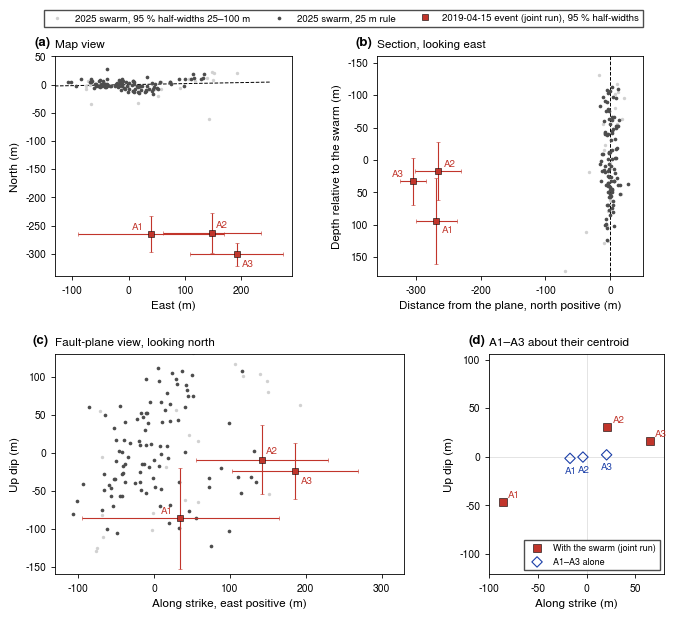

,label,along,up,nrm,ex95_m,ey95_m,ez95_m
0,A1,35.0,-86.0,-269.0,130.0,32.0,67.0
1,A2,143.0,-9.0,-266.0,87.0,35.0,45.0
2,A3,186.0,-24.0,-305.0,83.0,20.0,36.0


In [12]:
AID = {'20190415141735': 'A1', '20190415141739': 'A2', '20190415144315': 'A3'}; k = '2019A_full'
c = pd.read_csv(f'{DL}/catalogs/imsil_fmf_relocated_{k}.csv', dtype={'event_id': str}); r25k = pd.read_csv(f'{DL}/catalogs/reference_25m_fmf_{k}/DL_reference_25m.csv', dtype={'event_id': str})
c['emax'] = c[['ex95_m', 'ey95_m', 'ez95_m']].max(axis=1)
g25 = c[c.event_id.isin(r25k.event_id)]; lat0_, lon0_, z0_ = g25.latitude.mean(), g25.longitude.mean(), g25.depth_km.mean()
xyz = lambda d: np.c_[(d.longitude - lon0_) * 111.19e3 * np.cos(np.radians(lat0_)), (d.latitude - lat0_) * 111.19e3, (d.depth_km - z0_) * 1e3]
Pk = plane(xyz(g25)); Xk = xyz(c) - Pk['center']; usk = Pk['s'] if Pk['s'][0] > 0 else -Pk['s']; nvk = Pk['normal'] if Pk['normal'][1] > 0 else -Pk['normal']
c['along'], c['up'], c['nrm'], c['E'], c['N'], c['Z'] = Xk @ usk, -(Xk @ Pk['down']), Xk @ nvk, Xk[:, 0], Xk[:, 1], Xk[:, 2]
AA = c[c.event_id.isin(AID)].copy(); AA['label'] = AA.event_id.map(AID); AA = AA.sort_values('label')
q15 = grab('15_relocation_2019_events.ipynb', r'Tied to the swarm, A1-A3 sit (\d+-\d+) m south'); assert q15 == f'{-AA.nrm.max():.0f}-{-AA.nrm.min():.0f}', (q15, AA.nrm.round(0).tolist())
sw = c[~c.event_id.isin(AID)]; s25 = sw[sw.event_id.isin(r25k.event_id)]; s100 = sw[(sw.emax <= 100) & ~sw.event_id.isin(r25k.event_id)]
fact('a.south', f'{-AA.nrm.max():.0f}–{-AA.nrm.min():.0f}', 'this notebook = notebooks/15 (asserted)', 'distance south of the 2025 plane (m)')
fact('a.n99', f'{np.percentile(np.abs(s25.nrm), 99):.0f}', 'this notebook', '99 % of the 25 m events within this distance of the plane (m)')
nst_ = []
for eid in AID:
    pk_ = 0
    for f in glob.glob(f'{DL}/runs/hypodd_fmf_{k}/waveforms_100km/{eid}/*Z.sac'):
        h = obspy.read(f, headonly=True)[0].stats.sac; pk_ += int(h.get('a', -12345) > -1e4 or h.get('t0', -12345) > -1e4)
    nst_.append(pk_)
fact('a.nsta_links', f'{min(nst_)}–{max(nst_)}', 'runs/hypodd_fmf_2019A_full/waveforms_100km (inherited picks per event)')
fact('a.ey95', f'{AA.ey95_m.min():.0f}–{AA.ey95_m.max():.0f}', 'catalogs/imsil_fmf_relocated_2019A_full.csv', 'N-S 95 % half-widths (m)'); fact('a.ex95', f'{AA.ex95_m.min():.0f}–{AA.ex95_m.max():.0f}', 'catalogs/imsil_fmf_relocated_2019A_full.csv', 'E-W 95 % half-widths (m)')
fact('a.ez95', f'{AA.ez95_m.min():.0f}–{AA.ez95_m.max():.0f}', 'catalogs/imsil_fmf_relocated_2019A_full.csv'); fact('a.along', f'{AA.along.min():+.0f} to {AA.along.max():+.0f}'.replace('-', '−'), 'this notebook', 'along strike (m), east positive')
fact('a.up', f'{AA.up.min():+.0f} to {AA.up.max():+.0f}'.replace('-', '−'), 'this notebook', 'up dip (m)')
quote('a.robust', '15_relocation_2019_events.ipynb', r'dropping offset or changed-epoch stations keeps (\d+-\d+) m', lambda v: v.replace('-', '–'))
quote('a.sp_solo', '15_relocation_2019_events.ipynb', r'Mutual spacing: (\d+) m alone'); quote('a.sp_res', '15_relocation_2019_events.ipynb', r'Mutual spacing: \d+ m alone, (\d+) m re-solved'); quote('a.sp_joint', '15_relocation_2019_events.ipynb', r'Mutual spacing: \d+ m alone, \d+ m re-solved, (\d+) m joint')
quote('a.off_nawb', '15_relocation_2019_events.ipynb', r'NAWB\.S \+(\d+)'); quote('a.off_kch2', '15_relocation_2019_events.ipynb', r'KCH2\.S -(\d+)'); quote('a.off_jlsa', '15_relocation_2019_events.ipynb', r'JLSA\.S -(\d+)')
sol = pd.read_csv(f'{DL}/runs/hypodd_fmf_2019A_full/solo_A1A3/hypoDD.reloc', sep=r'\s+', header=None); sol = sol.sort_values(0).reset_index(drop=True)
Xs = np.c_[sol[4], sol[5], sol[6]]; sol['along'], sol['up'] = Xs @ usk, -(Xs @ Pk['down']); sol['label'] = ['A1', 'A2', 'A3']
XA, YA, XB, YB, XC, YC = (-130, 290), (-340, 50), (-360, 50), (180, -160), (-130, 330), (-160, 130)
HR, L0, B0 = 2.2, 0.62, 0.52; WA, WB, WC, WD = HR * np.ptp(XA) / np.ptp(YA), HR * np.ptp(XB) / abs(np.ptp(YB)), HR * np.ptp(XC) / np.ptp(YC), 1.75
FW, FH = 7.0, B0 + 2 * HR + 0.78 + 0.62
fig = plt.figure(figsize=(FW, FH)); axin = lambda l, b, w, h: fig.add_axes([l / FW, b / FH, w / FW, h / FH])
ax = [axin(L0, B0 + HR + 0.78, WA, HR), axin(L0 + WA + 0.85, B0 + HR + 0.78, WB, HR), axin(L0, B0, WC, HR), axin(L0 + WC + 0.85, B0, WD, HR)]
panels = ((ax[0], 'E', 'N', 'ex95_m', 'ey95_m', 'East (m)', 'North (m)', XA, YA), (ax[1], 'nrm', 'Z', 'ey95_m', 'ez95_m', 'Distance from the plane, north positive (m)', 'Depth relative to the swarm (m)', XB, YB),
          (ax[2], 'along', 'up', 'ex95_m', 'ez95_m', 'Along strike, east positive (m)', 'Up dip (m)', XC, YC))
for a, x, y, ex, ey, xl, yl, xr, yr in panels:
    a.scatter(s100[x], s100[y], s=6, color='0.82', lw=0, label='2025 swarm, 95 % half-widths 25–100 m', zorder=1)
    a.scatter(s25[x], s25[y], s=7, color='0.3', lw=0, label='2025 swarm, 25 m rule', zorder=2)
    for r_ in AA.itertuples():
        a.errorbar(getattr(r_, x), getattr(r_, y), xerr=getattr(r_, ex), yerr=getattr(r_, ey), fmt='s', ms=5, mfc='#c1352b', mec='black', mew=0.4, ecolor='#c1352b', elinewidth=0.8, capsize=1.5, zorder=4)
        off = {'A1': (4, -9), 'A2': (4, 3), 'A3': (-15, 3)}[r_.label] if x == 'nrm' else {'A1': (-14, 3), 'A2': (3, 4), 'A3': (4, -9)}[r_.label]
        a.annotate(r_.label, (getattr(r_, x), getattr(r_, y)), xytext=off, textcoords='offset points', fontsize=7, color='#c1352b')
    a.set_xlim(*xr); a.set_ylim(*yr); a.set_aspect('equal', adjustable='box'); a.set_xlabel(xl); a.set_ylabel(yl)
t_ = np.linspace(-250, 250, 2); ax[0].plot(t_ * Pk['s'][0], t_ * Pk['s'][1], 'k--', lw=0.7, zorder=0); ax[1].axvline(0, color='k', ls='--', lw=0.7, zorder=0)
ax[0].set_title('Map view', loc='left'); ax[1].set_title('Section, looking east', loc='left'); ax[2].set_title('Fault-plane view, looking north', loc='left')
for frame, mk, col, lab in ((AA.assign(al=AA.along - AA.along.mean(), uu=AA.up - AA.up.mean()), 's', '#c1352b', 'With the swarm (joint run)'), (sol.assign(al=sol.along - sol.along.mean(), uu=sol.up - sol.up.mean()), 'D', '#1b3fa8', 'A1–A3 alone')):
    ax[3].scatter(frame.al, frame.uu, marker=mk, s=28, facecolor=col if mk == 's' else 'none', edgecolor=col if mk == 'D' else 'black', lw=0.8 if mk == 'D' else 0.4, label=lab, zorder=3)
    for r_ in frame.itertuples(): ax[3].annotate(r_.label, (r_.al, r_.uu), xytext=(4, 3) if mk == 's' else (-4, -11), textcoords='offset points', fontsize=7, color=col)
ax[3].axhline(0, color='0.85', lw=0.5, zorder=0); ax[3].axvline(0, color='0.85', lw=0.5, zorder=0); ax[3].set_xlim(-100, 80); ax[3].set_aspect('equal', adjustable='datalim')
ax[3].set_xlabel('Along strike (m)'); ax[3].set_ylabel('Up dip (m)'); ax[3].set_title('A1–A3 about their centroid', loc='left')
ax[3].legend(loc='lower right', frameon=True, fontsize=6.5)
for a, s_ in zip(ax, 'abcd'): letter(a, s_)
h_, l_ = ax[0].get_legend_handles_labels(); h_.append(mpl.lines.Line2D([], [], marker='s', ls='none', mfc='#c1352b', mec='black', mew=0.4, ms=5)); l_.append('2019-04-15 event (joint run), 95 % half-widths')
fig.legend(h_, l_, loc='lower center', bbox_to_anchor=(0.5, (B0 + 2 * HR + 0.78 + 0.25) / FH), ncol=3, frameon=True, fontsize=7)
save(fig, 'Figure_07_2019_location'); record('Figure_07_2019_location', f'{DL}/catalogs/imsil_fmf_relocated_{k}.csv', f'{DL}/catalogs/reference_25m_fmf_{k}/DL_reference_25m.csv', f'{DL}/runs/hypodd_fmf_2019A_full/solo_A1A3/hypoDD.reloc')
display(AA[['label', 'along', 'up', 'nrm', 'ex95_m', 'ey95_m', 'ez95_m']].round(0))

## Facts quoted from the comparison and follow-up notebooks (12, 14)

In [13]:
N12 = '12_park2026_comparison.ipynb'
quote('pk.share', N12, r'our catalog holds (\d+)% of theirs', lambda v: v + '%')
for i_, p_ in enumerate(('P1', 'P2', 'P3', 'P4')): quote(f'pk.share_{p_}', N12, rf'{p_} (\d+)%' + (r', P' if p_ != 'P4' else r'\)'), lambda v: v + '%')
quote('pk.mag_rms', N12, r'Their magnitude scale is reproduced to ([\d.]+) rms'); quote('pk.below', N12, r'rms; (\d+%-\d+%) of the \d+ extra events are below Mw', lambda v: v.replace('%-', '–').rstrip('%') + '%')
quote('pk.extra', N12, r'of the (\d+) extra events are below Mw'); quote('pk.below_mw', N12, r'extra events are below Mw ([\d.]+)')
quote('pk.depth_hyp', N12, r'matches our well-recorded HYPOINVERSE events \(([\d.]+) km kim1983\)')
quote('pk.dd_sep', N12, r'two runs differ by ~(\d+) m absolute')
quote('pk.ext', N12, r'ours is (\d+ x \d+) m and \d+ m thick', lambda v: v.replace(' x ', ' × ')); quote('pk.thick', N12, r'ours is \d+ x \d+ m and (\d+) m thick')
quote('pk.D_ours', N12, r'their recipe on our events gives D = ([\d.]+-[\d.]+) m2/s', lambda v: v.replace('-', '–')); quote('pk.D_theirs', N12, r'\(theirs ([\d.]+-[\d.]+);', lambda v: v.replace('-', '–'))
quote('pk.spear', N12, r'station P/S ratios \(Spearman \+([\d.]+), p ='); quote('pk.spear_p', N12, r'Spearman \+[\d.]+, p = ([\d.]+)\)')
quote('pk.t_dist', N12, r'carried by inter-event distance \(t = (-?[\d.]+ / -?[\d.]+)\)', lambda v: v.replace('-', '−')); quote('pk.t_time', N12, r'rather than time \(t = (-?[\d.]+ / \+?[\d.]+)\)', lambda v: v.replace('-', '−'))
quote('pk.b_ours', N12, r'b on their scale agrees \(([\d.]+ \+/- [\d.]+)\)', lambda v: v.replace(' +/- ', ' ± ')); quote('pk.b_c2', N12, r'its level scales as 1/C2 \(([\d.]+ to [\d.]+) for C2', lambda v: v.replace(' to ', '–'))
quote('pk.depth_dd', N12, r'HypoDD clusters ([\d.]+-[\d.]+) km', lambda v: v.replace('-', '–'))
quote('pk.epi_kim1983', N12, r'HYPOINVERSE kim1983 median offset (N -?\d+ m, E -?\d+ m)', lambda v: v.replace('-', '−'))
N14 = '14_long_candidates_followup.ipynb'
for lab in ('A1', 'A2', 'A3'):
    quote(f'a.{lab}_ratio', N14, rf'{lab}\s+([\d.]+)\s+[\d.]+\s*\n'); quote(f'a.{lab}_ml', N14, rf'{lab}\s+[\d.]+\s+([\d.]+)\s*\n', lambda v: f'{float(v):.1f}')
quote('a.kma_share', N14, r'(\d+% / \d+% / \d+%)\s', lambda v: v.replace('%', '%'))
quote('b.jasa_x', N14, r'JASA ([\d.]+)x the pre-event level'); quote('b.imsb_x', N14, r'IMSB ([\d.]+)x'); quote('b.sim', N14, r'\b(0\.\d+ \(0\.\d+-0\.\d+\))\s', lambda v: v.replace('-', '–'))
quote('pk.n_theirs', N12, r'(\d+) \(P1-P4: \d+, \d+, \d+, \d+\)'); quote('pk.sta_theirs', N12, r'Main causes: (\d+) vs \d+ stations')
quote('pk.band_theirs', N12, r'Main causes: \d+ vs \d+ stations, (\d+-\d+) vs', lambda v: v.replace('-', '–')); quote('pk.depth_theirs', N12, r'(1\d\.\d-1\d\.\d) km \(joint inversion', lambda v: v.replace('-', '–'))
quote('pk.b_theirs', N12, r'(\d\.\d+ \+/- \d\.\d+) overall', lambda v: v.replace(' +/- ', ' ± ')); quote('pk.plane_theirs', N12, r'(\d+ / \d+) \(toward S\)', lambda v: v.replace(' / ', '° / ') + '°')
quote('pk.ext_theirs', N12, r'(\d+ m along strike x \d+) m vertical', lambda v: v.replace(' m along strike x ', ' × '))
quote('a.bin1', N14, r'\n(0\.\d+-0\.\d+)\s+\d+\s+\d+\s+0\.16\b', lambda v: v.replace('-', '–')); quote('a.bin2', N14, r'\n(0\.\d+-0\.\d+)\s+\d+\s+\d+\s+0\.43\b', lambda v: v.replace('-', '–'))
quote('rel.d6', '04_relocation_and_25m_reference.ipynb', r'D6: ML 1.9 shift with an onset window \(m\)\s+([\d.]+)')
quote('prev.n_ev', '04_relocation_and_25m_reference.ipynb', r'Earlier (\d+)-event relocation'); quote('prev.n_sta', '03_full_DL_catalog.ipynb', r'earlier PhaseNO \+ PyOcto run \((\d+) stations\)')
fact('long.stack_n', re.search(r'median stack of the (\d+) strongest', DEC.loc['D25', 'effect_on_counts']).group(1), 'docs/decisions.csv D25')
FC_ = open(f'{DL}/fmf/config.py').read(); fact('p.haenam_mad', re.search(r'^MAD_K = ([\d.]+)', FC_, re.M).group(1).rstrip('0').rstrip('.'), 'fmf/config.py (frozen Haenam code)'); fact('p.haenam_floor', re.search(r'^ABS_CC_FLOOR = ([\d.]+)', FC_, re.M).group(1), 'fmf/config.py (frozen Haenam code)')
quote('b.jasa_share', N14, r'(0\.\d+) / 0\.\d+; group-B network CC'); quote('b.kma20', N14, r'KMA events within 20 km of JASA: (\d+); coinciding'); quote('b.kma20_coinc', N14, r'coinciding with a group-B detection: (\d+)')
display(pd.DataFrame(FACTS).T[['value', 'source']].tail(45))

,value,source
pk.below,71–95\%,notebooks/12_park2026_comparison.ipynb
pk.extra,263,notebooks/12_park2026_comparison.ipynb
pk.below_mw,0.8,notebooks/12_park2026_comparison.ipynb
pk.depth_hyp,13.79,notebooks/12_park2026_comparison.ipynb
pk.dd_sep,520,notebooks/12_park2026_comparison.ipynb
pk.ext,237 × 225,notebooks/12_park2026_comparison.ipynb
pk.thick,37,notebooks/12_park2026_comparison.ipynb
pk.D_ours,0.34–0.40,notebooks/12_park2026_comparison.ipynb
pk.D_theirs,0.45–0.61,notebooks/12_park2026_comparison.ipynb
pk.spear,0.59,notebooks/12_park2026_comparison.ipynb


## Write facts.json, facts.tex and the figure sources

In [14]:
meta = dict(generated=datetime.datetime.now().astimezone().isoformat(timespec='seconds'), notebook=f'{NBD}/16_report_figures.ipynb', project_root=DL, n_facts=len(FACTS))
json.dump(dict(meta=meta, facts=FACTS), open(f'{REP}/facts.json', 'w'), indent=1, ensure_ascii=False)
lines = ['% facts.tex -- written by notebooks/16_report_figures.ipynb from facts.json; do not edit by hand.', f'% generated {meta["generated"]}; {len(FACTS)} macros.',
         r'\makeatletter', r'\newcommand\FactDef[2]{\expandafter\def\csname fact@#1\endcsname{#2}}',
         r'\DeclareRobustCommand\F[1]{\ifcsname fact@#1\endcsname\csname fact@#1\expandafter\endcsname\else\PackageError{facts}{Undefined fact #1}{Add it to notebook 16}\fi}', r'\makeatother']
lines += [rf'\FactDef{{{k}}}{{{v["value"]}}}' for k, v in sorted(FACTS.items())]
open(f'{REP}/facts.tex', 'w').write('\n'.join(lines) + '\n')
json.dump(SOURCES, open(f'{FIG}/sources.json', 'w'), indent=1)
figs = sorted(glob.glob(f'{FIG}/Figure_*.pdf')); print(f'{len(FACTS)} facts -> facts.json / facts.tex; {len(figs)} figures:', ', '.join(os.path.basename(f) for f in figs))

228 facts -> facts.json / facts.tex; 7 figures: Figure_01_station_map.pdf, Figure_02_swarm_timeline.pdf, Figure_03_geometry.pdf, Figure_04_migration.pdf, Figure_05_long_scan.pdf, Figure_06_2019_waveforms.pdf, Figure_07_2019_location.pdf


## Comprehensive summary

In [15]:
S = pd.DataFrame([
    ('Figures written (PDF + PNG, 300 dpi)', f'{len(figs)}: ' + ', '.join(os.path.basename(f)[:-4] for f in figs)),
    ('Facts written', f'{len(FACTS)} (computed here: {sum(not v["source"].startswith("notebooks/") for v in FACTS.values())}; quoted from executed notebooks: {sum(v["source"].startswith("notebooks/") for v in FACTS.values())})'),
    ('Asserted equal to the measuring notebook', 'front D for 0.5/1/2 h (nb11); A1-A3 distance from the plane (nb15); D23 counts (decision log); 24 KMA events among the 235 detections'),
    ('Swarm (template matching)', f'{FACTS["fmf.n_det"]["value"]} detections ({FACTS["fmf.n_ref"]["value"]} template events + {FACTS["fmf.n_new"]["value"]} new); first {FACTS["t.first"]["value"]}, last in the window {FACTS["t.last_window"]["value"]}, one more at {FACTS["fmf.late"]["value"]}'),
    ('Geometry (101 events)', f'plane {FACTS["geo.strike"]["value"]} / {FACTS["geo.dip"]["value"]}, RMS {FACTS["geo.rms"]["value"]} m, 99 % within {FACTS["geo.n99"]["value"]} m'),
    ('Front D (0.5 / 1 / 2 h)', f'{FACTS["mig.D05"]["value"]} / {FACTS["mig.D1"]["value"]} / {FACTS["mig.D2"]["value"]} m²/s'),
    ('2019-04-15 events', f'{FACTS["a.south"]["value"]} m south of the plane; S-window CC median {FACTS["a.cc_S_med"]["value"]} ({FACTS["a.cc_S_rng"]["value"]})'),
], columns=['quantity', 'value']); display(S)
print('Take-homes:')
print('1. The seven figures are drawn from the final products only; their PDF and PNG files and their input checksums (figures/sources.json) are in the report folder.')
print('2. Every number the report quotes is a macro from facts.tex; recomputed values that another notebook also printed are asserted equal to it.')
print('3. Rebuild: re-run this notebook, then compile report.tex with tectonic (see the report README).')

,quantity,value
0,"Figures written (PDF + PNG, 300 dpi)","7: Figure_01_station_map, Figure_02_swarm_timeline, Figure_03_geometry, Figure_04_migration, Figure_05_long_scan, Figure_06_2019_waveforms, Figure_07_2019_location"
1,Facts written,228 (computed here: 128; quoted from executed notebooks: 100)
2,Asserted equal to the measuring notebook,front D for 0.5/1/2 h (nb11); A1-A3 distance from the plane (nb15); D23 counts (decision log); 24 KMA events among the 235 detections
3,Swarm (template matching),"235 detections (28 template events + 207 new); first 19:57:38, last in the window 00:53:41, one more at 04:23:32"
4,Geometry (101 events),"plane 268.7 / 88.2, RMS 7.4 m, 99 % within 15 m"
5,Front D (0.5 / 1 / 2 h),0.50 / 0.59 / 0.63 m²/s
6,2019-04-15 events,266–305 m south of the plane; S-window CC median 0.43 (−0.11–0.92)


Take-homes:
1. The seven figures are drawn from the final products only; their PDF and PNG files and their input checksums (figures/sources.json) are in the report folder.
2. Every number the report quotes is a macro from facts.tex; recomputed values that another notebook also printed are asserted equal to it.
3. Rebuild: re-run this notebook, then compile report.tex with tectonic (see the report README).
